# 2. EDA

Este notebook es el **segundo paso del pipeline**, donde se hace un análisis exploratorio completo del corpus: **6 medios · 3 años · opinión, política, economía**

## 0. Configuración y dependencias

In [ ]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings('ignore')


In [2]:
if Path.cwd().name == 'notebooks':
    os.chdir('..')

DATA_DIR   = Path('data')
PROC_DIR   = Path('data/processed')
EMB_DIR    = Path('embeddings')
OUTPUT_DIR = Path('output')
for d in [PROC_DIR, EMB_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MEDIOS = [
    'elconfidencial',
    'eldiario',
    'publico',
    'okdiario',
    'elpais',
    'elmundo',
]

print(f'Working dir: {Path.cwd()}')
print(f'Medios: {MEDIOS}')

Working dir: /Users/blancagallardo/PycharmProjects/TFM
Medios: ['elconfidencial', 'eldiario', 'publico', 'okdiario', 'elpais', 'elmundo']



## 0.1. Carga de datos limpios

Los datos han sido procesados por `1_limpieza.ipynb` y aquí solo se cargan los JSON limpios.

In [4]:
df = pd.read_parquet(PROC_DIR / "corpus_limpio.parquet")
print(f"Total artículos: {len(df)}")
print(df.groupby("medio").size().to_string())

Total artículos: 258524
medio
El Confidencial    37178
El Mundo           31458
El País            68664
OKDiario           55985
Público            26602
elDiario.es        38637


In [4]:
PALETTE = {
    'El Confidencial': '#5B9BD5',
    'elDiario.es':     '#E07B7B',
    'El Mundo':        '#F2A65A',
    'El País':         '#4F7DAA',
    'OKDiario':        '#68A882',
    'Público':         '#9E78BE',
}
MEDIOS_ORDEN = ['El País', 'El Confidencial', 'elDiario.es', 'El Mundo', 'OKDiario', 'Público']
COLORS = [PALETTE[m] for m in MEDIOS_ORDEN]

PALETTE_TEMA = {'politica': '#5B8DB8', 'economia': '#C8973C', 'opinion': '#C07868'}

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})
print("Paleta y estilo configurados")


Paleta y estilo configurados


---
### 1. Resumen del dataset

In [5]:
rows = []
for medio in MEDIOS_ORDEN:
    sub = df[df['medio'] == medio]
    trunc = sub['truncado'].sum() if 'truncado' in sub.columns else None
    trunc_pct = f"{100*trunc/len(sub):.1f}%" if (trunc is not None and len(sub) > 0) else "—"
    rows.append({
        'Medio':            medio,
        'Artículos':        len(sub),
        'Política':         (sub['tema']=='politica').sum(),
        'Economía':         (sub['tema']=='economia').sum(),
        'Opinión':          (sub['tema']=='opinion').sum(),
        'Autores únicos':   sub['autor'].nunique(),
        'Fecha inicio':     sub['fecha_dt'].min().strftime('%Y-%m-%d') if sub['fecha_dt'].notna().any() else '—',
        'Fecha fin':        sub['fecha_dt'].max().strftime('%Y-%m-%d') if sub['fecha_dt'].notna().any() else '—',
        'Truncados':        trunc_pct,
    })

summary = pd.DataFrame(rows).set_index('Medio')
summary.loc['TOTAL'] = {
    'Artículos': len(df),
    'Política': (df['tema']=='politica').sum(),
    'Economía': (df['tema']=='economia').sum(),
    'Opinión':  (df['tema']=='opinion').sum(),
    'Autores únicos': df['autor'].nunique(),
    'Fecha inicio': df['fecha_dt'].min().strftime('%Y-%m-%d'),
    'Fecha fin':    df['fecha_dt'].max().strftime('%Y-%m-%d'),
    'Truncados': f"{100*df['truncado'].sum()/len(df):.1f}%" if 'truncado' in df.columns else '—',
}
summary['Artículos'] = summary['Artículos'].astype(int)
summary['Política']  = summary['Política'].astype(int)
summary['Economía']  = summary['Economía'].astype(int)
summary['Opinión']   = summary['Opinión'].astype(int)
summary['Autores únicos'] = summary['Autores únicos'].astype(int)
print(summary.to_string())


                 Artículos  Política  Economía  Opinión  Autores únicos Fecha inicio   Fecha fin Truncados
Medio                                                                                                     
El País              68664     49891     17422     1351            5131   2023-03-27  2026-04-07      5.2%
El Confidencial      37178     24270     12244      664            1609   2023-03-15  2026-03-25      0.0%
elDiario.es          38637     29701      8293      643            2095   2023-03-14  2026-03-18      0.0%
El Mundo             31458     27824      2758      876            1883   2023-03-27  2026-04-03     26.8%
OKDiario             55985     37460     17806      719             523   2023-03-19  2026-04-09      0.0%
Público              26602     21181      4784      637            1266   2023-03-28  2026-03-25      0.0%
TOTAL               258524    190327     63307     4890           12230   2023-03-14  2026-04-09      4.6%


---
### 2. Distribución de artículos por medio

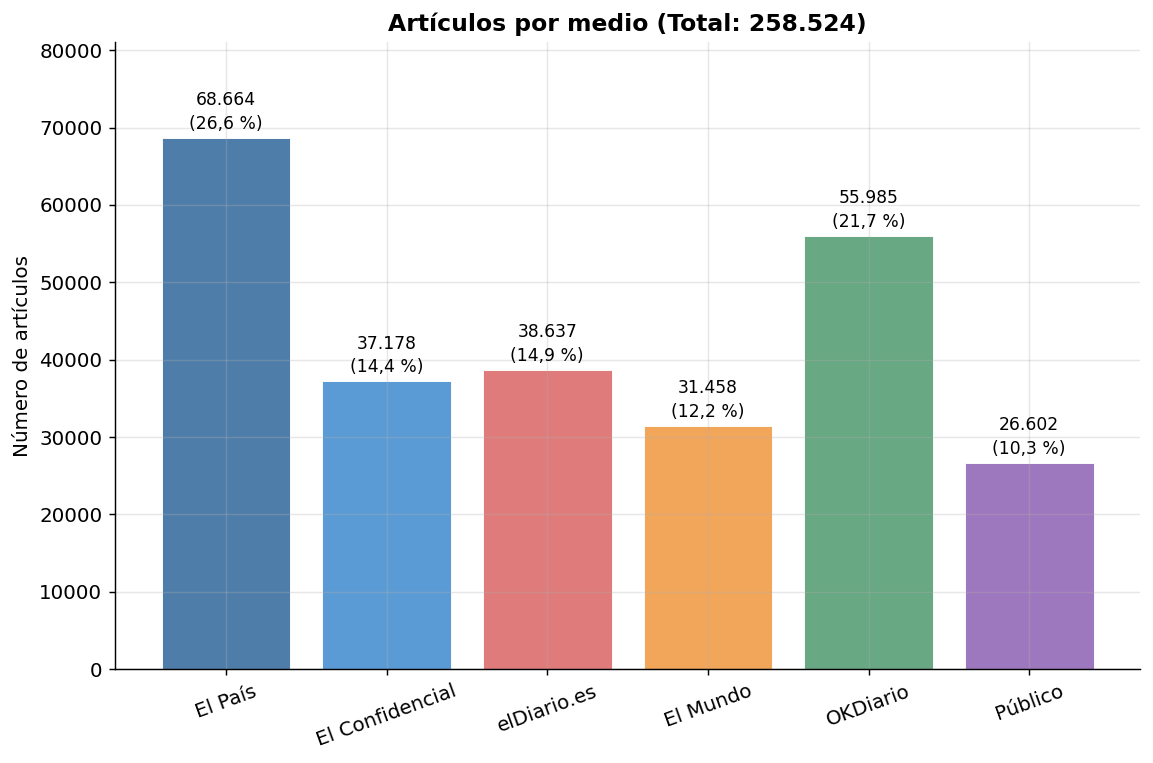

In [6]:
def fmt_es(val, dec=0):
    s = f"{val:,.{dec}f}"
    return s.replace(',', 'X').replace('.', ',').replace('X', '.') if dec > 0 \
           else s.replace(',', '.')

counts = df[df['medio'].isin(MEDIOS_ORDEN)].groupby('medio').size().reindex(MEDIOS_ORDEN)
total  = counts.sum()
pcts   = counts / total * 100

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(MEDIOS_ORDEN, counts.values, color=COLORS,
              edgecolor='white', linewidth=0.5)
ax.set_ylabel('Número de artículos')
ax.set_title(
    f'Artículos por medio (Total: {fmt_es(total)})',
    fontsize=13, fontweight='bold'
)
ax.set_ylim(0, counts.max() * 1.18)
ax.tick_params(axis='x', rotation=20)
for bar, val, pct in zip(bars, counts.values, pcts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.01,
        f'{fmt_es(val)}\n({fmt_es(pct, dec=1)} %)',
        ha='center', va='bottom', fontsize=9.5, linespacing=1.4
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_01_articulos_por_medio.png', bbox_inches='tight')
plt.show()


El corpus presenta un **desequilibrio notable** entre medios: uno o dos de ellos acumulan una fracción desproporcionada del total de artículos, mientras que otros tienen una presencia mucho más reducida. Esta asimetría es habitual en corpus periodísticos scrapeados, donde la facilidad de acceso y la frecuencia de publicación varían significativamente entre cabeceras.

**Implicación para el desarollo:** en los análisis comparativos entre medios segun el modelo conviene aplicar alguna estrategia de control del volumen (ponderación, submuestreo estratificado o métricas normalizadas) para que el medio más grande no domine los resultados por pura masa documental.

---
### 3. Distribución por tema

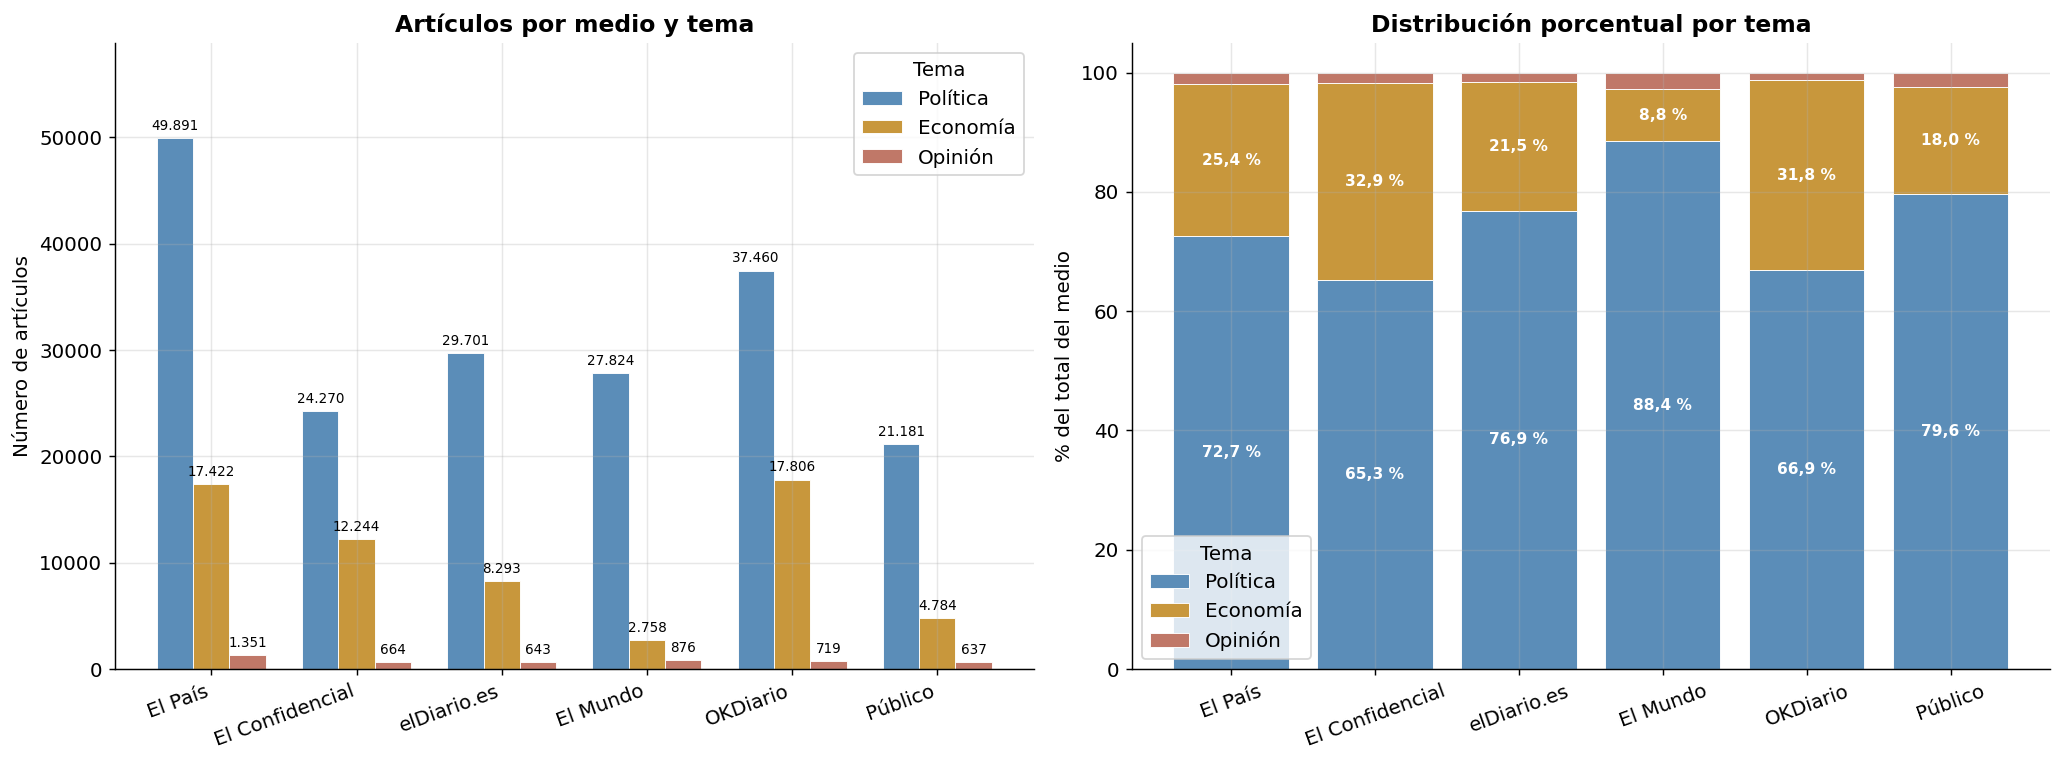

In [7]:
temas = ['politica', 'economia', 'opinion']
LABELS_TEMA = {'politica': 'Política', 'economia': 'Economía', 'opinion': 'Opinión'}

tema_medio = (
    df[df['medio'].isin(MEDIOS_ORDEN)]
    .groupby(['medio', 'tema'])
    .size()
    .unstack(fill_value=0)
    .reindex(MEDIOS_ORDEN)[temas]
)
tema_medio_pct = tema_medio.div(tema_medio.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# barras verticales agrupadas (conteo)
x = np.arange(len(MEDIOS_ORDEN))
width = 0.25
for j, tema in enumerate(temas):
    bars = axes[0].bar(
        x + j * width, tema_medio[tema].values, width=width,
        label=LABELS_TEMA[tema], color=PALETTE_TEMA[tema],
        edgecolor='white', linewidth=0.5
    )
    for bar, val in zip(bars, tema_medio[tema].values):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + tema_medio.values.max() * 0.01,
            fmt_es(val),
            ha='center', va='bottom', fontsize=7.5
        )

axes[0].set_xticks(x + width)
axes[0].set_xticklabels(MEDIOS_ORDEN, rotation=20, ha='right')
axes[0].set_ylabel('Número de artículos')
axes[0].set_title('Artículos por medio y tema', fontsize=13, fontweight='bold')
axes[0].set_ylim(0, tema_medio.values.max() * 1.18)
axes[0].legend(title='Tema')

# barras verticales apiladas (porcentaje)
bottom = np.zeros(len(MEDIOS_ORDEN))
for tema in temas:
    vals = tema_medio_pct[tema].values
    bars = axes[1].bar(
        MEDIOS_ORDEN, vals, bottom=bottom,
        label=LABELS_TEMA[tema], color=PALETTE_TEMA[tema],
        edgecolor='white', linewidth=0.5
    )
    for bar, pct, bot in zip(bars, vals, bottom):
        if pct > 4:
            axes[1].text(
                bar.get_x() + bar.get_width() / 2,
                bot + pct / 2,
                f'{fmt_es(pct, dec=1)} %',
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold'
            )
    bottom += vals

axes[1].set_ylabel('% del total del medio')
axes[1].set_title('Distribución porcentual por tema', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='Tema')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_02_distribucion_tema.png', bbox_inches='tight')
plt.show()


La distribución temática no es homogénea, todos contienen muchos más articulos de política.

**Implicación para el desarollo:** la variable tema puede actuará como un factor de confusión en los embeddings si no se controla: artículos de economía de diferentes medios pueden acabar más próximos entre sí que artículos del mismo medio pero de distinto tema.

---
### 4. Distribución temporal

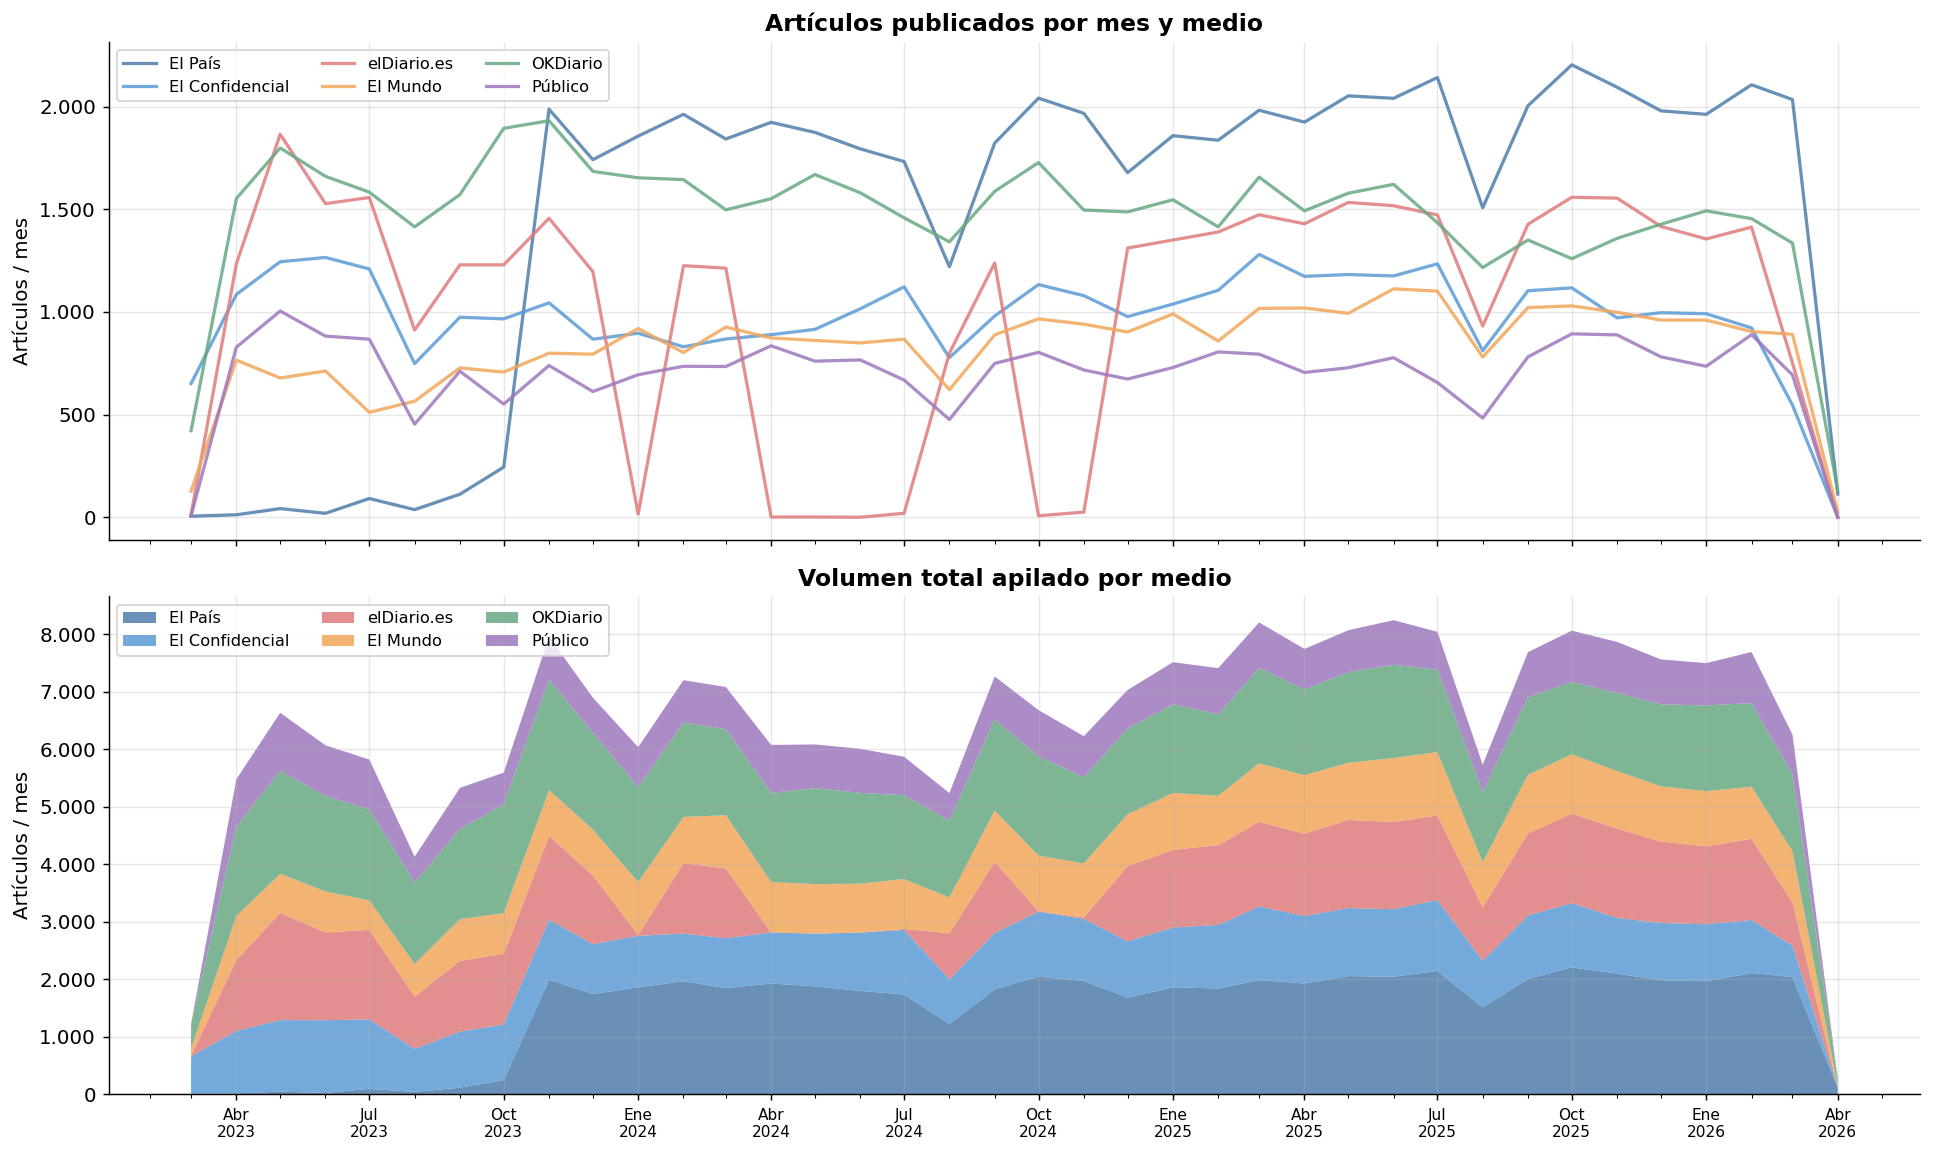

In [8]:
df_time = df[df['medio'].isin(MEDIOS_ORDEN) & df['fecha_dt'].notna()].copy()
df_time['mes'] = df_time['fecha_dt'].dt.to_period('M').dt.to_timestamp()

monthly = (
    df_time.groupby(['mes', 'medio'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=MEDIOS_ORDEN, fill_value=0)
)

MESES_ES = {1:'Ene',2:'Feb',3:'Mar',4:'Abr',5:'May',6:'Jun',
            7:'Jul',8:'Ago',9:'Sep',10:'Oct',11:'Nov',12:'Dic'}

def fmt_fecha(x, pos=None):
    d = mdates.num2date(x)
    return f"{MESES_ES[d.month]}\n{d.year}"

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for medio in MEDIOS_ORDEN:
    axes[0].plot(monthly.index, monthly[medio], label=medio,
                 color=PALETTE[medio], linewidth=1.8, alpha=0.85)
axes[0].set_title('Artículos publicados por mes y medio', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Artículos / mes')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_es(int(v))))
axes[0].legend(loc='upper left', ncol=3, fontsize=9)
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: fmt_es(int(v)))
)

axes[1].stackplot(
    monthly.index,
    [monthly[m] for m in MEDIOS_ORDEN],
    labels=MEDIOS_ORDEN,
    colors=COLORS, alpha=0.85
)
axes[1].set_title('Volumen total apilado por medio', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Artículos / mes')
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: fmt_es(int(v)))
)
axes[1].legend(loc='upper left', ncol=3, fontsize=9)

axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(fmt_fecha))
axes[1].tick_params(axis='x', which='major', labelsize=8.5, pad=4)
axes[1].xaxis.set_minor_locator(mdates.MonthLocator())
axes[1].set_xlabel('')

fig.autofmt_xdate(rotation=0, ha='center')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_04_temporal.png', bbox_inches='tight')
plt.show()


El gráfico muestra la evolución de la producción de artículos en seis medios digitales en España entre 2023 y abril de 2026. El País muestra un crecimiento sostenido y el mayor volumen. elDiario.es presenta fuertes caídas puntuales, probablemente por errores del scrapper. OKDiario, El Confidencial, El Mundo y Público compiten en un nivel intermedio, con volúmenes relativamente similares. En conjunto, el sector crece de unos 6.000 a más de 8.000 artículos mensuales, con bajadas estacionales en vacaciones. La caída en abril de 2026 se debe a que es el més que se realizó el scrapper y esta incompleto.

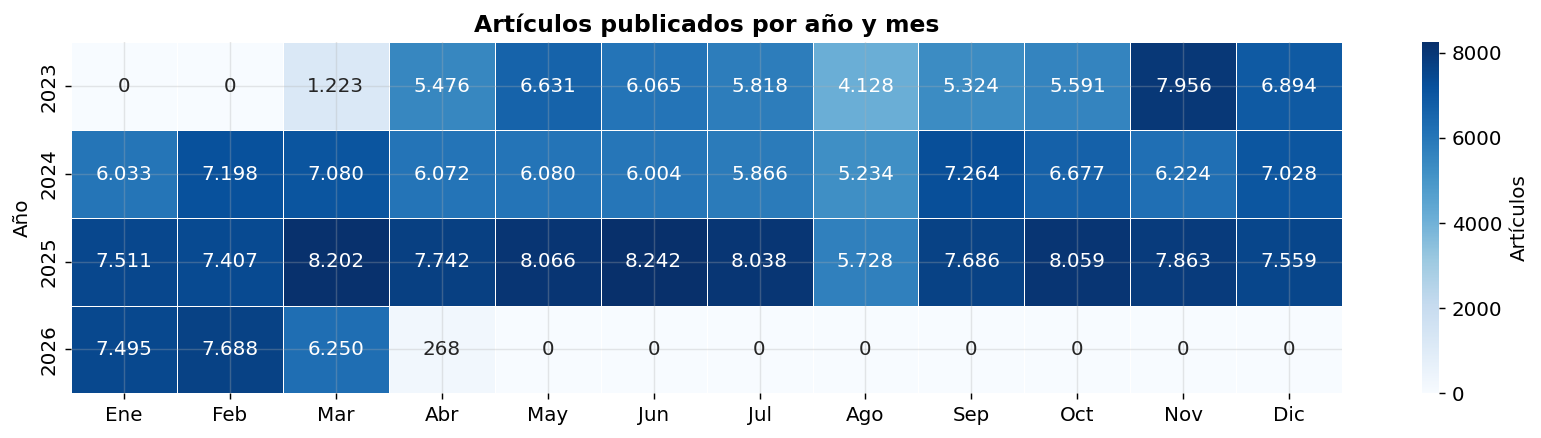

In [9]:
df_time['anio'] = df_time['fecha_dt'].dt.year
df_time['mes_num'] = df_time['fecha_dt'].dt.month

pivot_cal = df_time.groupby(['anio', 'mes_num']).size().unstack(fill_value=0)
pivot_cal.columns = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

pivot_cal_annot = pivot_cal.map(lambda v: fmt_es(int(v)))
fig, ax = plt.subplots(figsize=(13, 3.5))
sns.heatmap(pivot_cal, annot=pivot_cal_annot, fmt='', cmap='Blues',
            linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'Artículos'},
            ax=ax)
ax.set_title('Artículos publicados por año y mes', fontsize=13, fontweight='bold')
ax.set_ylabel('Año')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_05_heatmap_calendario.png', bbox_inches='tight')
plt.show()


El mapa de calor permite detectar **lagunas de cobertura** y asimetrías anuales

In [10]:
# Gaps de cobertura
meses_rango = pd.period_range(
    df_time['fecha_dt'].min().to_period('M'),
    df_time['fecha_dt'].max().to_period('M'),
    freq='M'
)

print(f"Rango total: {meses_rango[0]} → {meses_rango[-1]} ({len(meses_rango)} meses)\n")
print("Meses sin cobertura por medio:")
for medio in MEDIOS_ORDEN:
    sub = df_time[df_time['medio'] == medio]
    meses_con_data = set(sub['fecha_dt'].dt.to_period('M').unique())
    gaps = [str(m) for m in meses_rango if m not in meses_con_data]
    estado = f"{len(gaps)} gaps: {gaps}" if gaps else "sin gaps"
    print(f"  {medio:>17s}: {estado}")


Rango total: 2023-03 → 2026-04 (38 meses)

Meses sin cobertura por medio:
            El País: sin gaps
    El Confidencial: 1 gaps: ['2026-04']
        elDiario.es: 2 gaps: ['2024-06', '2026-04']
           El Mundo: sin gaps
           OKDiario: sin gaps
            Público: 1 gaps: ['2026-04']


La mayoría de los medios muestran continuidad sin interrupciones. El País, El Mundo y OKDiario no tienen gaps, mientras que El Confidencial y Público solo presentan uno en abril de 2026 (mes incompleto debido que es cuando se hizo el scrapp). elDiario.es destaca con dos gaps, especialmente el de junio de 2024, probablemente por problemas técnicos del scrapper más que por falta real de actividad.

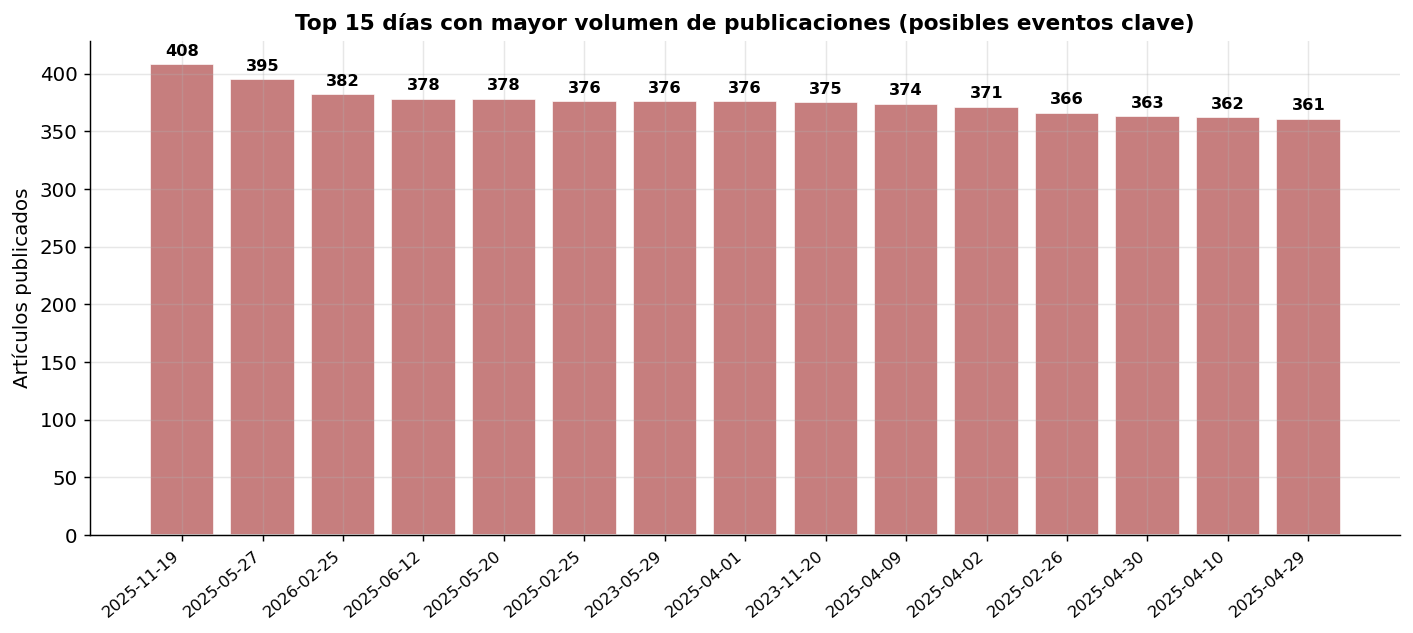


Top 15 días de mayor actividad:
  2025-11-19   408 arts  |  El País:97  elDiario.es:89  OKDiario:82  El Mundo:49  Público:47  El Confidencial:44
  2025-05-27   395 arts  |  El País:96  OKDiario:78  elDiario.es:77  El Confidencial:56  El Mundo:52  Público:36
  2026-02-25   382 arts  |  El País:92  OKDiario:72  Público:59  El Mundo:57  elDiario.es:56  El Confidencial:46
  2025-06-12   378 arts  |  El País:79  OKDiario:78  elDiario.es:76  El Confidencial:67  El Mundo:44  Público:34
  2025-05-20   378 arts  |  El País:90  elDiario.es:74  OKDiario:67  El Confidencial:65  El Mundo:49  Público:33
  2025-02-25   376 arts  |  El País:91  elDiario.es:77  OKDiario:76  El Confidencial:59  Público:43  El Mundo:30
  2023-05-29   376 arts  |  elDiario.es:144  OKDiario:84  Público:65  El Confidencial:58  El Mundo:22  El País:3
  2025-04-01   376 arts  |  El País:83  elDiario.es:70  El Confidencial:69  OKDiario:68  El Mundo:54  Público:32
  2023-11-20   375 arts  |  El País:94  elDiario.es:70  OKDiari

In [11]:
# Top 15 días con más publicaciones (spikes editoriales)
daily = (
    df[df['fecha_dt'].notna()]
    .groupby(df['fecha_dt'].dt.date)
    .size()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(range(len(daily)), daily.values,
              color='#C07070', edgecolor='white', alpha=0.9)
ax.set_xticks(range(len(daily)))
ax.set_xticklabels([str(d) for d in daily.index], rotation=40, ha='right', fontsize=9)
for bar, val in zip(bars, daily.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 5, fmt_es(val),
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Top 15 días con mayor volumen de publicaciones (posibles eventos clave)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Artículos publicados')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_16_spikes.png', bbox_inches='tight')
plt.show()

print("\nTop 15 días de mayor actividad:")
for d, v in daily.items():
    breakdown = df[df['fecha_dt'].dt.date == d]['medio'].value_counts().to_dict()
    bstr = '  '.join(f"{m}:{n}" for m, n in breakdown.items())
    print(f"  {d}  {v:>4} arts  |  {bstr}")


Los picos de publicación identificados no responden únicamente a eventos aislados, sino a episodios de alta densidad informativa donde múltiples variables (políticas, judiciales y sociales) se activan simultáneamente.

Se observan dos patrones claros:
- Picos asociados a eventos discretos: como el 29/05/2023 (elecciones 28M) o el 20/11/2023 (investidura y amnistía), donde podemos pensar que un único acontecimiento actúa como driver principal y genera un aumento sincronizado en todos los medios.
- Picos por acumulación de factores: especialmente entre febrero y junio de 2025, donde no hay un evento único dominante, sino una superposición de señales (tensión política, casos judiciales, protestas y contexto económico).
Además, fechas como el 19/11/2025 muestran el efecto de eventos recurrentes o simbólicos (20N) que amplifican la cobertura mediática de forma predecible, mientras que el 25/02/2026 encaja en un patrón de convergencia temática, donde diferentes agendas (política, judicial y económica) coinciden temporalmente.

En conjunto, el gráfico refleja que los máximos de producción no dependen solo de grandes eventos, sino de la coincidencia y acumulación de múltiples estímulos informativos, lo que incrementa significativamente el volumen total publicado.

---
### 5. Análisis de autores

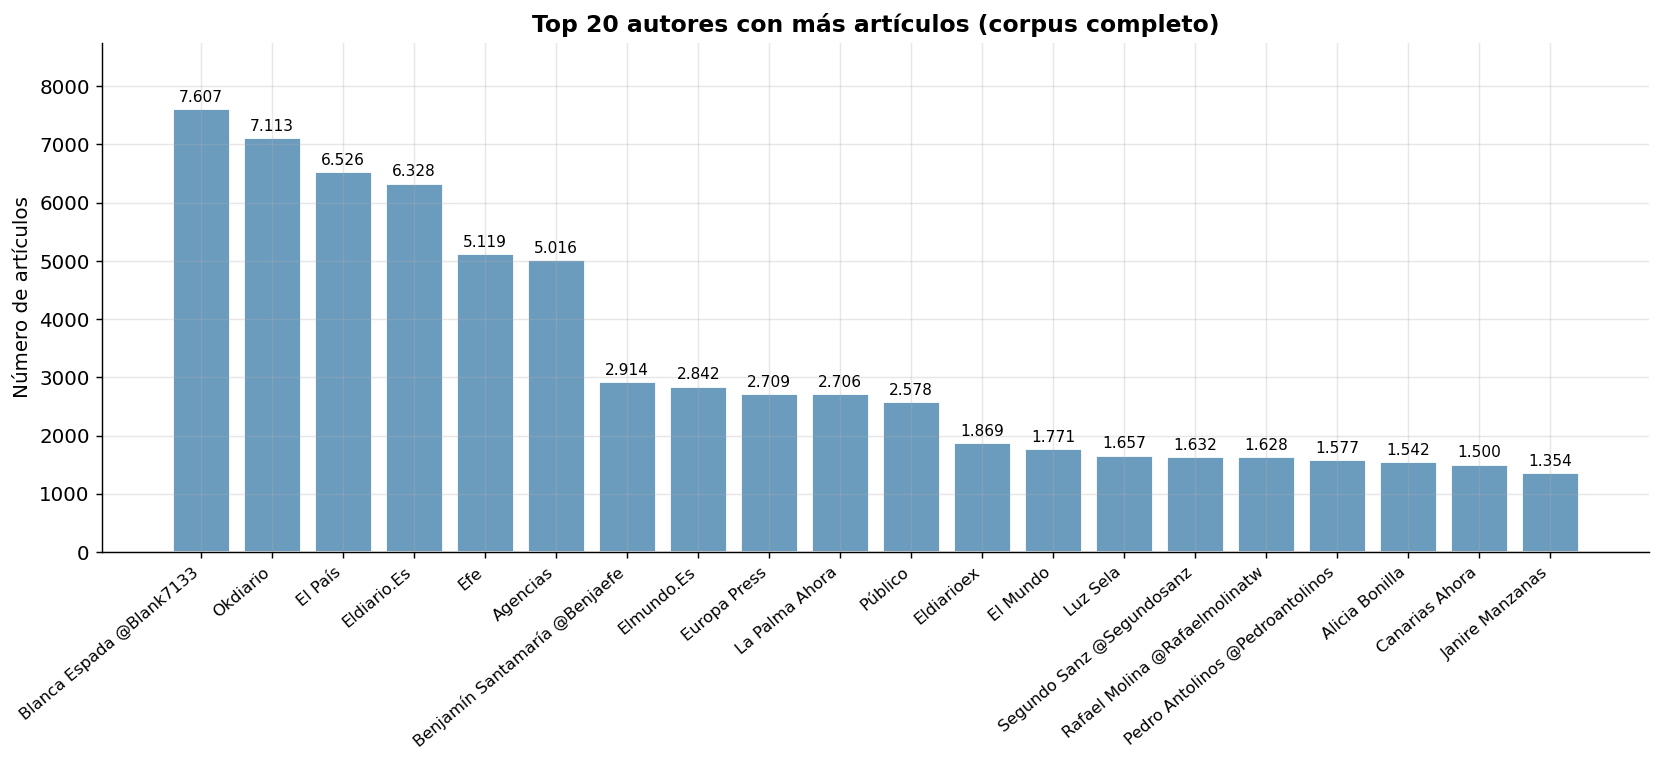

In [12]:
def normalizar_autor(nombre):
    if not isinstance(nombre, str):
        return ''
    return ' '.join(nombre.strip().split()).title()

df['autor_norm'] = df['autor'].apply(normalizar_autor)

top_autores = (
    df[df['autor_norm'].str.strip() != '']
    ['autor_norm'].value_counts()
    .head(20)
)

fig, ax = plt.subplots(figsize=(13, 6))
bars = ax.bar(top_autores.index, top_autores.values,
              color='#6B9BBD', edgecolor='white')
for bar, val in zip(bars, top_autores.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + top_autores.max() * 0.01,
        fmt_es(val),
        ha='center', va='bottom', fontsize=8.5
    )
ax.set_title('Top 20 autores con más artículos (corpus completo)', fontsize=13, fontweight='bold')
ax.set_ylabel('Número de artículos')
ax.set_ylim(0, top_autores.max() * 1.15)
ax.tick_params(axis='x', rotation=40)
plt.setp(ax.get_xticklabels(), ha='right', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_06_top_autores_global.png', bbox_inches='tight')
plt.show()


Pocos autores concentran una fracción muy elevada de los artículos, mientras que la mayoría de colaboradores tienen una presencia muy esporádica. Los autores más prolíficos son columnistas fijos o periodistas de plantilla que publican diariamente o varias veces por semana y su estilo y sus temas habituales imprimirán una huella fuerte en los embeddings de su medio.

**Implicación para el desarollo:** se ha de tener en cuenta que ciertos clusters pueden están dominados por la firma de un único periodista más que por la temática del artículo.

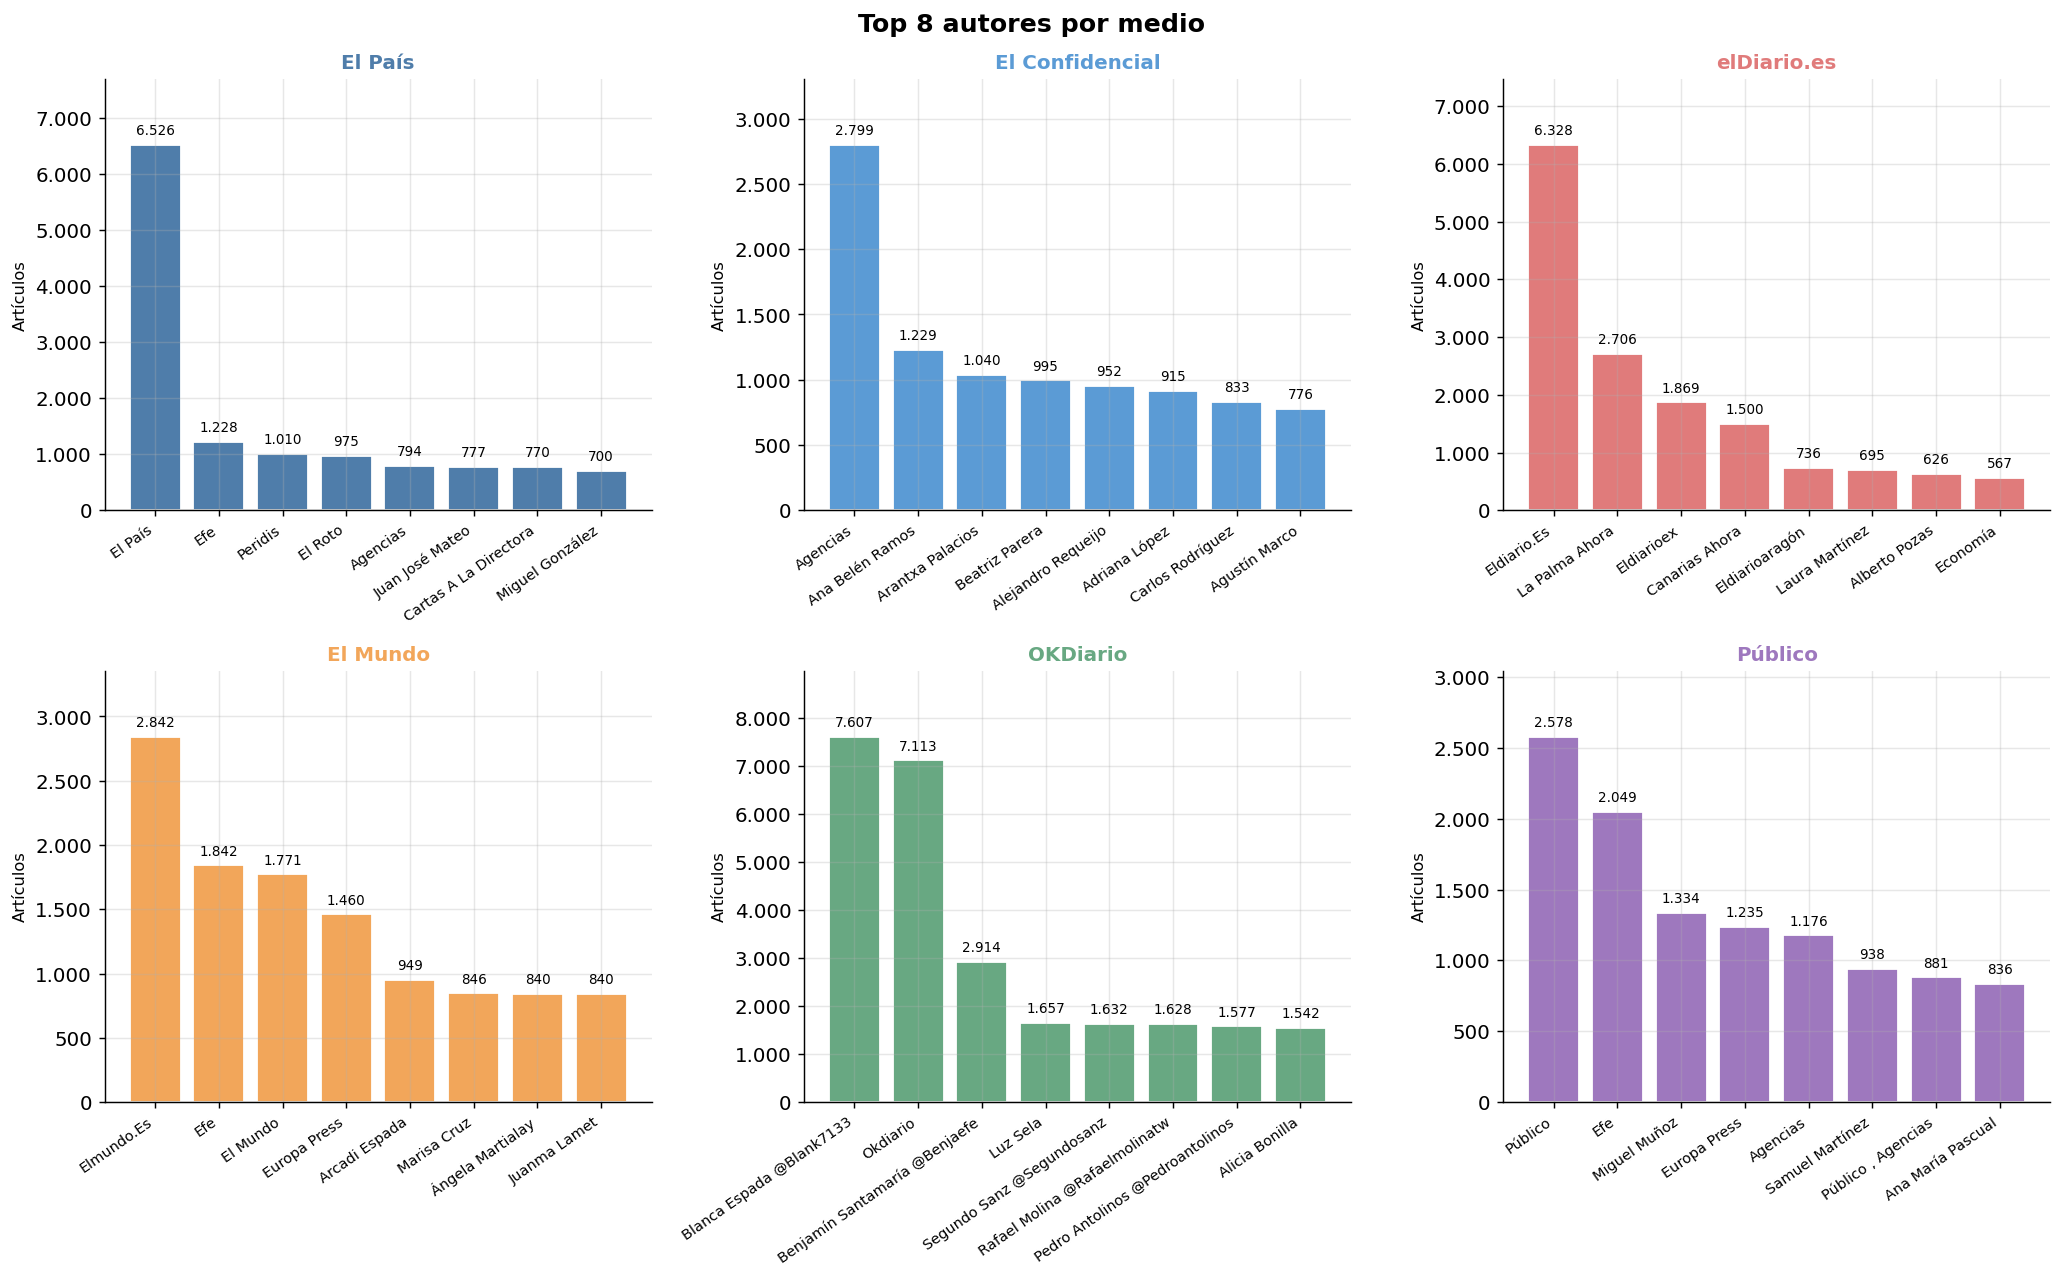

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, medio in zip(axes, MEDIOS_ORDEN):
    sub = df[(df['medio'] == medio) & (df['autor_norm'].str.strip() != '')]
    top = sub['autor_norm'].value_counts().head(8)
    bars = ax.bar(range(len(top)), top.values,
                  color=PALETTE[medio], edgecolor='white')
    ax.set_xticks(range(len(top)))
    ax.set_xticklabels(top.index, rotation=35, ha='right', fontsize=8)
    ax.set_ylim(0, top.max() * 1.18)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_es(int(v))))
    for bar, val in zip(bars, top.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + top.max() * 0.02,
            fmt_es(val),
            ha='center', va='bottom', fontsize=7.5
        )
    ax.set_title(medio, fontsize=11, fontweight='bold', color=PALETTE[medio])
    ax.set_ylabel('Artículos', fontsize=9)

plt.suptitle('Top 8 autores por medio', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_07_top_autores_medio.png', bbox_inches='tight')
plt.show()


Cada medio tiene sus propios autores, con muy poco solapamiento entre cabeceras. Esto confirma que la autoría es un rasgo diferenciador fuerte entre medios, lo que refuerza la hipótesis de que los embeddings capturarán tanto el estilo del medio como el del autor.

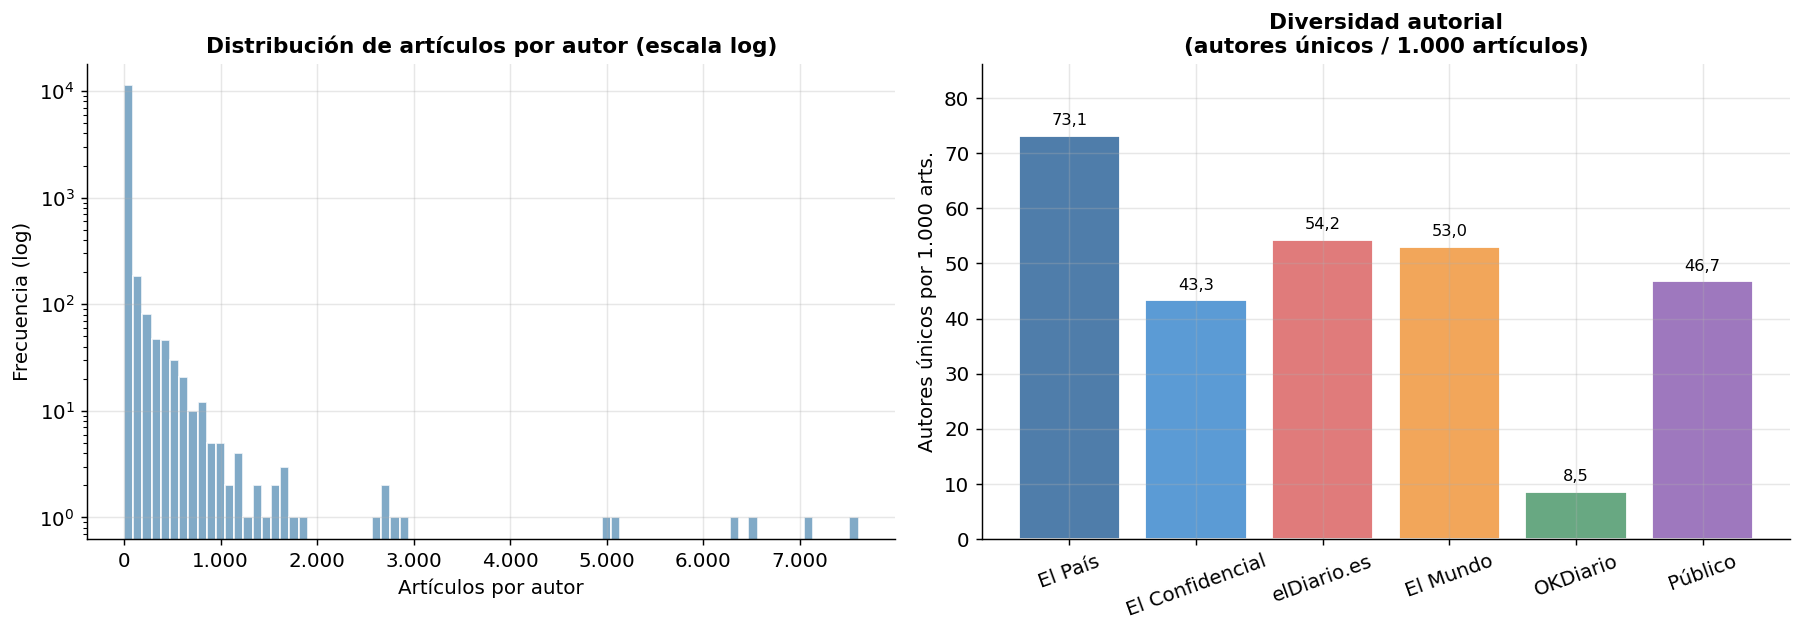


Total autores únicos en el corpus: 11.819
Autores con solo 1 artículo: 7.141 (60,4 %)
Top 1% de autores acapara: 51,7 % de los artículos


In [14]:
# Distribución de artículos por autor (concentración)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

autor_counts = df[df['autor_norm'].str.strip() != '']['autor_norm'].value_counts()

axes[0].hist(autor_counts.values, bins=80, color='#6B9BBD', edgecolor='white', alpha=0.85)
axes[0].set_yscale('logs')
axes[0].set_title('Distribución de artículos por autor (escala logs)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Artículos por autor')
axes[0].set_ylabel('Frecuencia (logs)')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_es(int(v))))

# Richness: autores únicos por 1000 artículos
richness = {}
for medio in MEDIOS_ORDEN:
    sub = df[(df['medio'] == medio) & (df['autor_norm'].str.strip() != '')]
    richness[medio] = sub['autor_norm'].nunique() / len(sub) * 1000 if len(sub) > 0 else 0

bars = axes[1].bar(richness.keys(), richness.values(),
                   color=[PALETTE[m] for m in richness.keys()], edgecolor='white')
axes[1].set_title('Diversidad autorial\n(autores únicos / 1.000 artículos)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Autores únicos por 1.000 arts.')
axes[1].set_ylim(0, max(richness.values()) * 1.18)
axes[1].tick_params(axis='x', rotation=20)
for bar, (m, v) in zip(bars, richness.items()):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(richness.values()) * 0.02,
        fmt_es(v, dec=1),
        ha='center', va='bottom', fontsize=9
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_08_autores_distribucion.png', bbox_inches='tight')
plt.show()

print(f"\nTotal autores únicos en el corpus: {fmt_es(df['autor_norm'].nunique())}")
print(f"Autores con solo 1 artículo: {fmt_es((autor_counts == 1).sum())} ({fmt_es(100*(autor_counts==1).mean(), dec=1)} %)")
print(f"Top 1% de autores acapara: {fmt_es(autor_counts.head(int(len(autor_counts)*0.01)).sum()/len(df)*100, dec=1)} % de los artículos")


La distribución del histograma confirma la larga cola: la inmensa mayoría de los autores solo aparece una o muy pocas veces, mientras que el extremo superior agrupa a los columnistas de plantilla con cientos de artículos.

---
### 6. Artículos truncados (El Mundo y El País)

          Truncados  Total  % Truncados
medio                                  
El Mundo       8425  31458    26.781741
El País        3591  68664     5.229815


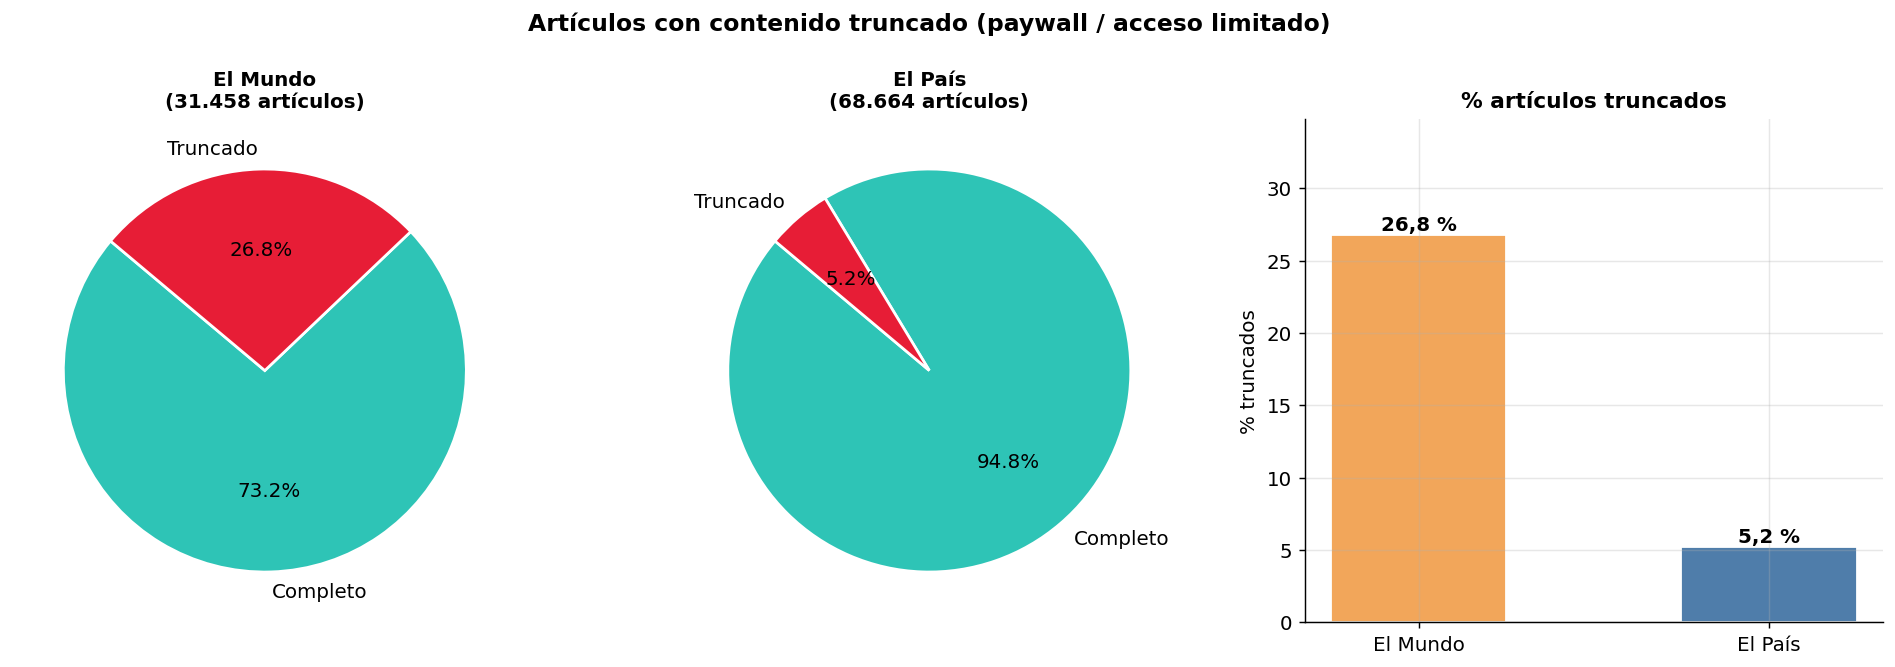

In [16]:
trunc_medios = ['El Mundo', 'El País']
trunc_df = df[df['medio'].isin(trunc_medios)].copy()
trunc_df['truncado'] = trunc_df['truncado'].fillna(False).astype(bool)

trunc_summary = trunc_df.groupby('medio')['truncado'].agg(['sum', 'count'])
trunc_summary['pct'] = trunc_summary['sum'] / trunc_summary['count'] * 100
trunc_summary.columns = ['Truncados', 'Total', '% Truncados']
print(trunc_summary.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Absoluto por medio
for ax_i, medio in zip([0, 1], trunc_medios):
    sub = trunc_df[trunc_df['medio'] == medio]
    vc = sub['truncado'].value_counts()
    labels = ['Completo', 'Truncado']
    vals   = [vc.get(False, 0), vc.get(True, 0)]
    colors = ['#2EC4B6', '#E71D36']
    axes[ax_i].pie(vals, labels=labels, colors=colors, autopct='%1.1f%%',
                   startangle=140, wedgeprops={'edgecolor':'white','linewidth':1.5})
    axes[ax_i].set_title(f'{medio}\n({fmt_es(len(sub))} artículos)', fontsize=11, fontweight='bold')

# Comparativa de % truncados
pcts = [trunc_summary.loc[m, '% Truncados'] for m in trunc_medios]
bars = axes[2].bar(trunc_medios, pcts, color=[PALETTE['El Mundo'], PALETTE['El País']], edgecolor='white', width=0.5)
for bar, p in zip(bars, pcts):
    axes[2].text(bar.get_x() + bar.get_width()/2, p + 0.3,
                 f'{fmt_es(p, dec=1)} %', ha='center', fontsize=11, fontweight='bold')
axes[2].set_ylim(0, max(pcts) * 1.3)
axes[2].set_title('% artículos truncados', fontsize=12, fontweight='bold')
axes[2].set_ylabel('% truncados')

plt.suptitle('Artículos con contenido truncado (paywall / acceso limitado)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_09_truncados.png', bbox_inches='tight')
plt.show()


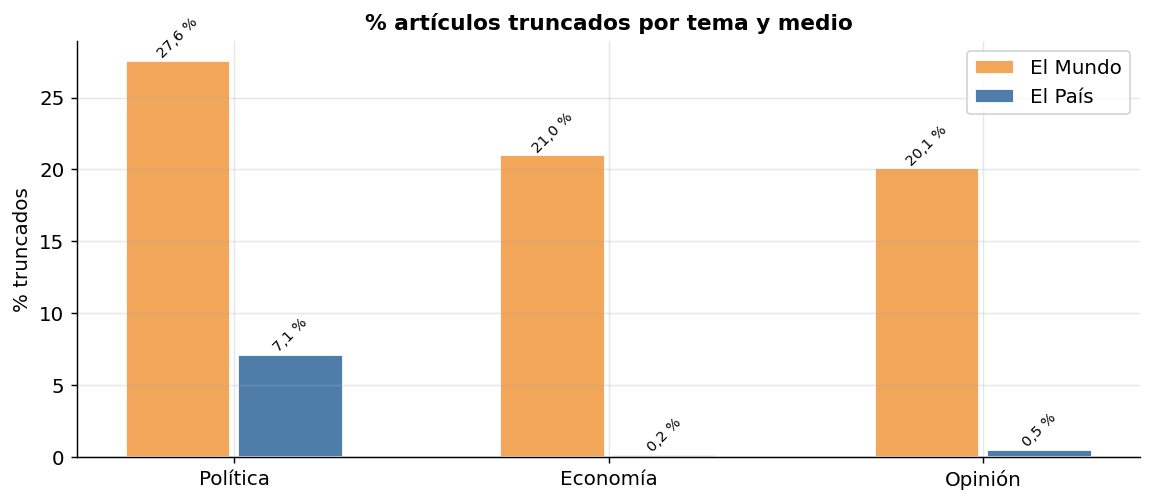

In [17]:
trunc_tema = (
    trunc_df.groupby(['medio', 'tema'])['truncado']
    .agg(trunc='sum', total='count')
    .assign(pct=lambda x: x['trunc'] / x['total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4))
for i, medio in enumerate(trunc_medios):
    sub = trunc_tema[trunc_tema['medio'] == medio].set_index('tema').reindex(['politica','economia','opinion'])
    x = [j + i*0.3 for j in range(3)]
    bars = ax.bar(x, sub['pct'].fillna(0), width=0.28, color=PALETTE[medio], label=medio, edgecolor='white')
    for bar, p in zip(bars, sub['pct'].fillna(0)):
        ax.text(bar.get_x() + bar.get_width()/2, p + 0.2, f'{fmt_es(p, dec=1)} %',
                ha='center', fontsize=8, rotation=45)

ax.set_xticks([0.15, 1.15, 2.15])
ax.set_xticklabels(['Política', 'Economía', 'Opinión'])
ax.set_title('% artículos truncados por tema y medio', fontsize=12, fontweight='bold')
ax.set_ylabel('% truncados')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_10_truncados_tema.png', bbox_inches='tight')
plt.show()


El truncamiento afecta exclusivamente a El Mundo y El País, que disponen de contenido de pago. La tasa de truncamiento varía entre ambos medios y entre temas: los artículos de opinión, habitualmente más cortos y de libre acceso suelen presentar menor truncamiento que los de política.

**Implicación para el desarollo:** Los artículos truncados tienen un texto significativamente más corto, lo que puede generar embeddings de menor calidad y hacer que se agrupen por longitud en lugar de por contenido. En el País si que puedo eliminar los articulos truncados, en canvio en el Mundo és un 26%.

---
### 7. Completitud del dataset

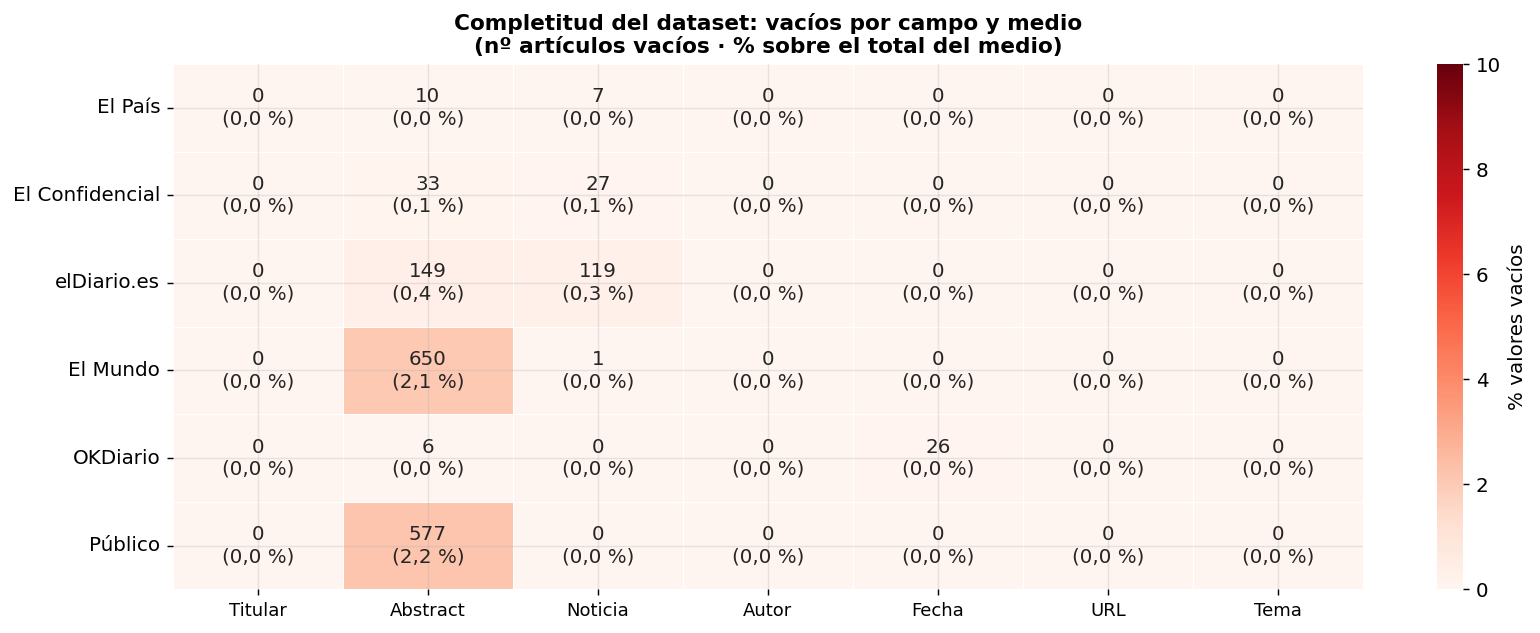

In [18]:
campos = ['titular', 'abstract', 'noticia', 'autor', 'fecha', 'url', 'tema']
LABELS_CAMPO = {
    'titular':'Titular', 'abstract':'Abstract', 'noticia':'Noticia',
    'autor':'Autor', 'fecha':'Fecha', 'url':'URL', 'tema':'Tema'
}

#Tabla: nº vacíos, % vacío por campo y medio
rows = []
for medio in MEDIOS_ORDEN:
    sub = df[df['medio'] == medio]
    total = len(sub)
    for campo in campos:
        if campo not in sub.columns:
            continue
        n_vacio = (sub[campo].isna() | (sub[campo].astype(str).str.strip() == '')).sum()
        pct = 100 * n_vacio / total if total else 0
        rows.append({'Medio': medio, 'Campo': campo, 'Total': total,
                     'Vacíos': n_vacio, 'Pct': pct})

miss_long = pd.DataFrame(rows)
miss_pct  = miss_long.pivot(index='Medio', columns='Campo', values='Pct').reindex(MEDIOS_ORDEN)[campos]
miss_n    = miss_long.pivot(index='Medio', columns='Campo', values='Vacíos').reindex(MEDIOS_ORDEN)[campos]

#  Heatmap con vacíos y porcentaje
annot_combined = miss_n.map(lambda v: fmt_es(int(v))) + "\n(" + miss_pct.map(lambda v: fmt_es(v, dec=1)) + " %)"

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    miss_pct,
    annot=annot_combined, fmt='',
    cmap='Reds',
    linewidths=0.5, linecolor='white',
    vmin=0, vmax=max(miss_pct.values.max() + 2, 10),
    cbar_kws={'label': '% valores vacíos'},
    ax=ax
)
ax.set_title('Completitud del dataset: vacíos por campo y medio\n(nº artículos vacíos · % sobre el total del medio)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([LABELS_CAMPO.get(c, c) for c in campos], rotation=0, fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_11_missingness.png', bbox_inches='tight')
plt.show()


El mapa muestra cuántos artículos tienen cada campo vacío y qué porcentaje representan sobre el total del medio.

- **Titular y URL** son los campos más completos en todos los medios: tasas de ausencia cercanas al 0 %.
- **Abstract** es el campo más incompleto: no siempre está disponible en el HTML scrapeado y algunos medios no lo publican de forma sistemática.
- **Autor** presenta ausencias notables en medios con mucho contenido de agencia o sin firma explícita.
- **Noticia** (el cuerpo del artículo) tiene un porcentaje de vacíos bajo, lo que indica que el corpus está en buenas condiciones para el análisis semántico.

**Implicación para el desarrolo:** filtrar artículos con `noticia` vacía para evitar vectores degenerados.

---
### 8.Longitud del texto

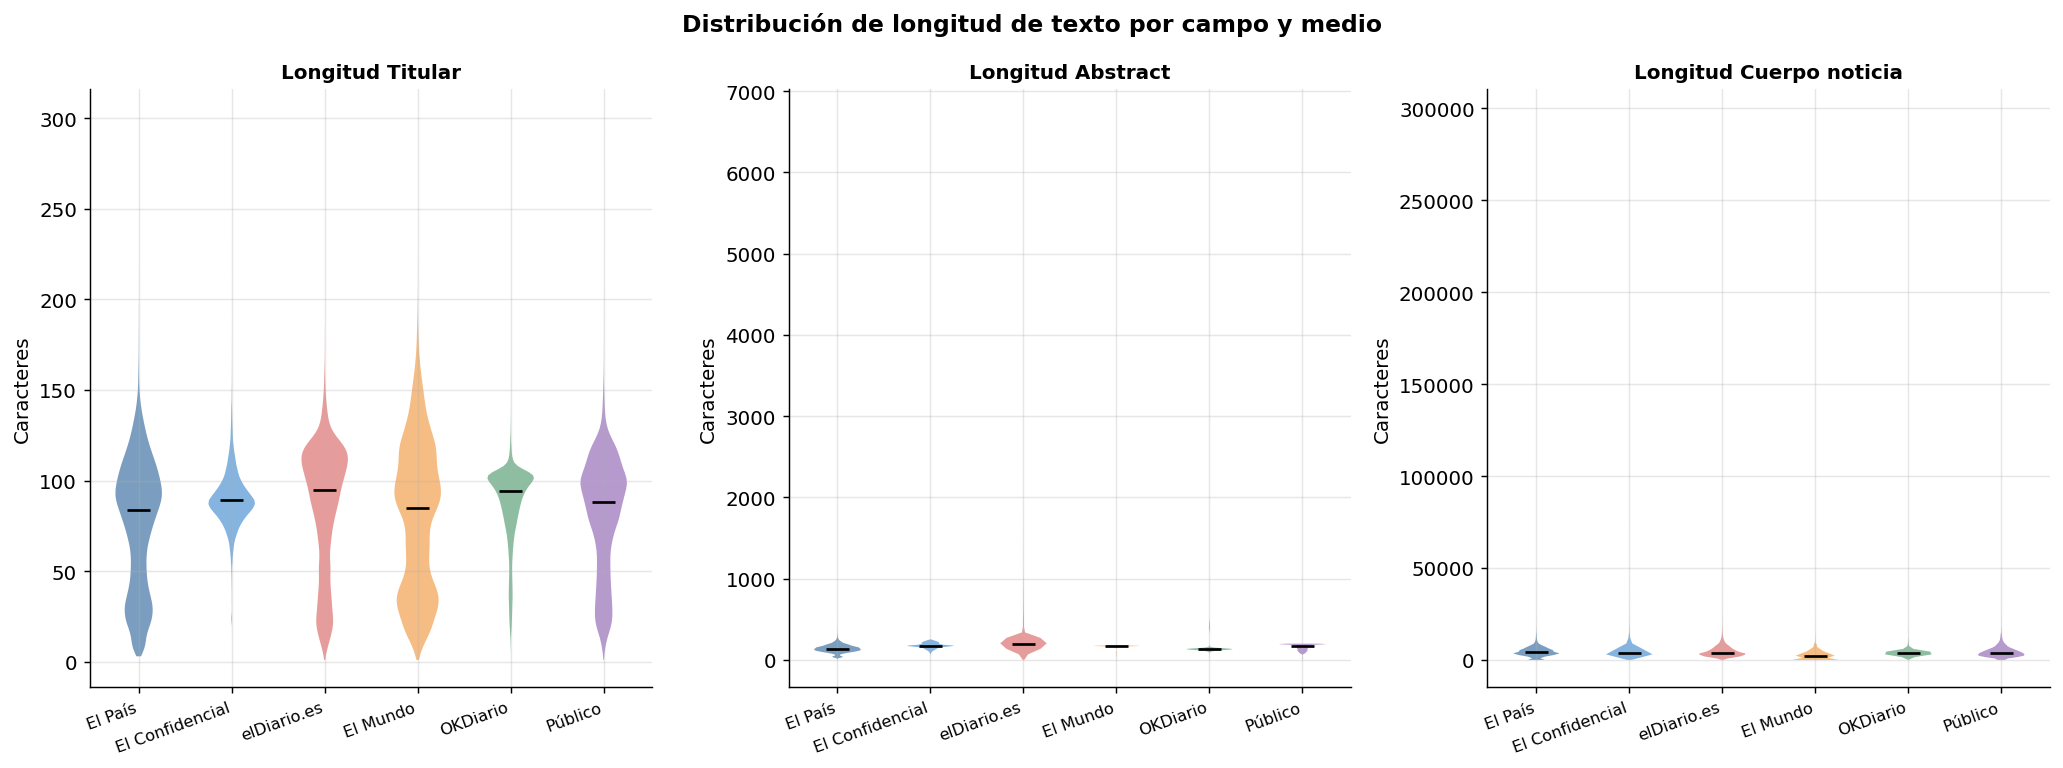

In [19]:
# Longitud del texto (titular, abstract, noticia) por medio
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=False)

for ax, campo, titulo, color_base in zip(
    axes,
    ['titular', 'abstract', 'noticia'],
    ['Titular', 'Abstract', 'Cuerpo noticia'],
    ['#6B9BBD', '#D4B86A', '#4AADA0']
):
    data_plot = [
        df[(df['medio'] == m) & (df[campo].str.len() > 0)][campo].str.len().dropna()
        for m in MEDIOS_ORDEN
    ]
    parts = ax.violinplot(data_plot, positions=range(len(MEDIOS_ORDEN)),
                          showmedians=True, showextrema=False)
    for i, (pc, medio) in enumerate(zip(parts['bodies'], MEDIOS_ORDEN)):
        pc.set_facecolor(PALETTE[medio])
        pc.set_alpha(0.75)
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(1.5)
    ax.set_xticks(range(len(MEDIOS_ORDEN)))
    ax.set_xticklabels(MEDIOS_ORDEN, rotation=20, ha='right', fontsize=9)
    ax.set_title(f'Longitud {titulo}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Caracteres')

plt.suptitle('Distribución de longitud de texto por campo y medio', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_12_longitud_texto.png', bbox_inches='tight')
plt.show()


En general, los titulares muestran más diferencias entre medios: suelen estar entre 75 y 125 caracteres, con elDiario.es y OKDiario tendiendo a titulares más largos, y El Confidencial más compacto. En las entradillas, los medios son bastante homogéneos, con textos generalmente cortos y por debajo de 500 caracteres, aunque elDiario.es destaca ligeramente por ser más extenso. En el cuerpo de la noticia, hay una gran variabilidad y una escala mucho mayor, aunque la mayoría de los artículos se concentran en rangos relativamente bajos, con pocos casos extremadamente largos.

En conjunto, se observa una fuerte estandarización del periodismo digital, donde las principales diferencias entre medios se encuentran en los titulares, mientras que el resto de la estructura tiende a ser bastante similar.

---
### 9. Duplicados en titulares

Titulares 'en directo' excluidos: 2.227
Titulares duplicados (filas)   : 12.760 (5,0 % del corpus sin directos)
Titulares únicos afectados     : 4.203

Clasificación de titulares duplicados:
  Scraper (mismo medio, misma fecha): 3.449
  Agencia (medios distintos): 450
  Actualización (mismo medio, distinta fecha): 304


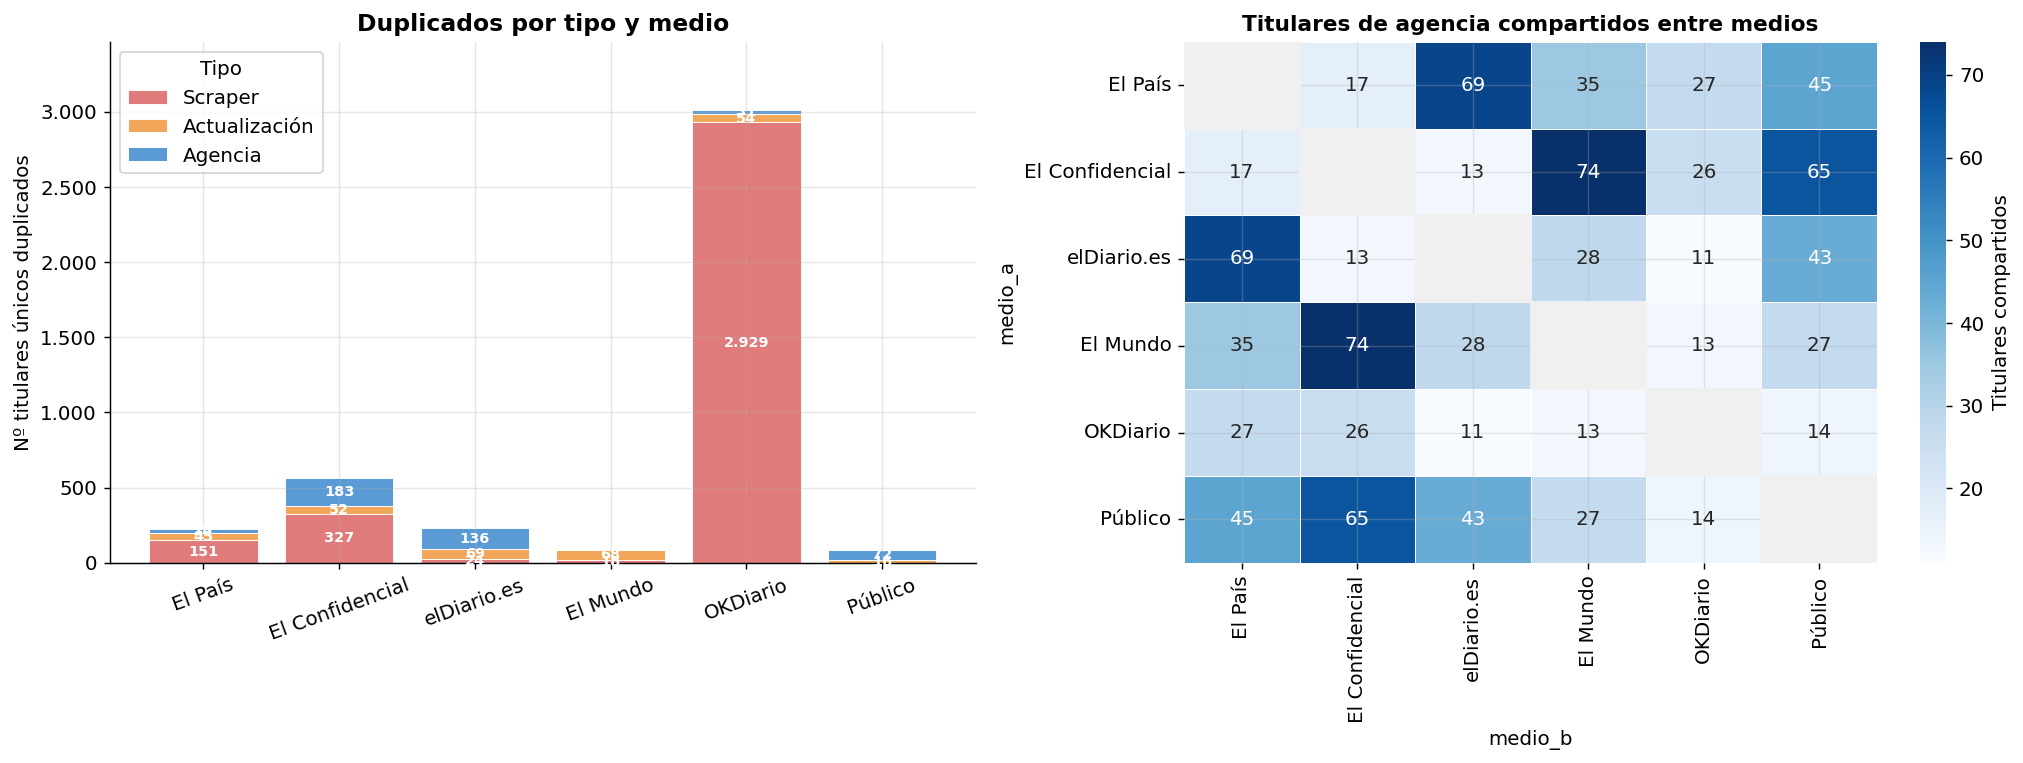

In [20]:
# Detección y clasificación de duplicados en titulares

df['titular_norm'] = df['titular'].str.lower().str.strip()
df['fecha_dia']    = df['fecha_dt'].dt.date

# Excluir formatos recurrentes (en directo, última hora…)
PATRONES_DIRECTO = [
    'en directo', 'última hora', 'minuto a minuto',
    'tiempo real', 'en vivo', 'directo\s*[|│]', '[|│]\s*directo',
]
mask_directo    = df['titular_norm'].str.contains(
    '|'.join(PATRONES_DIRECTO), case=False, na=False, regex=True
)
df_sd           = df[~mask_directo]          # sd = sin directos
print(f"Titulares 'en directo' excluidos: {fmt_es(mask_directo.sum())}")

# Duplicados sobre el corpus sin directos
dup_mask  = df_sd.duplicated('titular_norm', keep=False) & (df_sd['titular_norm'] != '')
dup_exact = df_sd[dup_mask].copy()
print(f"Titulares duplicados (filas)   : {fmt_es(len(dup_exact))} "
      f"({fmt_es(100*len(dup_exact)/len(df_sd), dec=1)} % del corpus sin directos)")
print(f"Titulares únicos afectados     : {fmt_es(dup_exact['titular_norm'].nunique())}\n")

# Clasificar cada grupo: scraper / actualización / agencia
grp        = dup_exact.groupby('titular_norm')
n_medios   = grp['medio'].transform('nunique')
n_fechas   = grp['fecha_dia'].transform('nunique')

dup_exact['tipo'] = 'scraper'
dup_exact.loc[n_medios > 1,                        'tipo'] = 'agencia'
dup_exact.loc[(n_medios == 1) & (n_fechas > 1),   'tipo'] = 'actualizacion'

COLORES_TIPO = {'scraper':'#E07B7B', 'actualizacion':'#F2A65A', 'agencia':'#5B9BD5'}
LABELS_TIPO  = {'scraper':'Scraper', 'actualizacion':'Actualización', 'agencia':'Agencia'}

resumen = dup_exact.drop_duplicates('titular_norm')['tipo'].value_counts()
print("Clasificación de titulares duplicados:")
DESC = {'scraper':'mismo medio, misma fecha',
        'actualizacion':'mismo medio, distinta fecha',
        'agencia':'medios distintos'}
for tipo, n in resumen.items():
    print(f"  {LABELS_TIPO[tipo]} ({DESC[tipo]}): {fmt_es(n)}")

# barras apiladas por medio y tipo
conteo = (
    dup_exact.drop_duplicates('titular_norm')
    .groupby(['medio','tipo']).size()
    .unstack(fill_value=0)
    .reindex(MEDIOS_ORDEN, fill_value=0)
    .reindex(columns=['scraper','actualizacion','agencia'], fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bottom = np.zeros(len(MEDIOS_ORDEN))
for tipo in ['scraper','actualizacion','agencia']:
    vals = conteo[tipo].values
    bars = axes[0].bar(MEDIOS_ORDEN, vals, bottom=bottom,
                       label=LABELS_TIPO[tipo],
                       color=COLORES_TIPO[tipo], edgecolor='white', linewidth=0.5)
    for bar, v, bot in zip(bars, vals, bottom):
        if v > 5:
            axes[0].text(bar.get_x() + bar.get_width()/2, bot + v/2,
                         fmt_es(v), ha='center', va='center',
                         fontsize=8, color='white', fontweight='bold')
    bottom += vals
axes[0].set_title('Duplicados por tipo y medio', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Nº titulares únicos duplicados')
axes[0].set_ylim(0, conteo.sum(axis=1).max() * 1.15)
axes[0].tick_params(axis='x', rotation=20)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_es(int(v))))
axes[0].legend(title='Tipo')

# heatmap agencia (vectorizado)
dup_ag = dup_exact[dup_exact['tipo'] == 'agencia']

ag_medios = dup_ag[['titular_norm','medio']].drop_duplicates()
pares = ag_medios.merge(ag_medios, on='titular_norm', suffixes=('_a','_b'))
pares = pares[pares['medio_a'] != pares['medio_b']]
cross = pares.groupby(['medio_a','medio_b']).size().unstack(fill_value=0)
cross = cross.reindex(index=MEDIOS_ORDEN, columns=MEDIOS_ORDEN, fill_value=0)

cross_annot = cross.map(lambda v: fmt_es(int(v)))
sns.heatmap(cross, annot=cross_annot, fmt='', cmap='Blues',
            linewidths=0.5, linecolor='white',
            mask=(cross == 0), ax=axes[1],
            cbar_kws={'label':'Titulares compartidos'})
for i in range(len(MEDIOS_ORDEN)):
    axes[1].add_patch(plt.Rectangle((i,i),1,1,fill=True,color='#f0f0f0',zorder=3))
axes[1].set_title('Titulares de agencia compartidos entre medios',
                   fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_meta_18_duplicados.png', bbox_inches='tight')
plt.show()


In [21]:
# Muestra de duplicados por tipo (3 ejemplos de cada tipo)
N = 3

def mostrar_copias(titular_n, df_ref):
    copias = df_ref[df_ref['titular_norm'] == titular_n][['medio','fecha','titular','noticia']]
    print(f'\n  ► "{copias.iloc[0]["titular"]}"')
    print(f'  Aparece {fmt_es(len(copias))} veces:')
    for idx, (_, row) in enumerate(copias.iterrows(), 1):
        print(f'\n  [{idx}] {row["medio"]}  |  {str(row["fecha"])[:10]}')
        cuerpo = str(row['noticia']).strip()
        lineas = [l for l in cuerpo.splitlines() if l.strip()][:5]
        if not lineas:
            lineas = [s.strip() + '.' for s in cuerpo.split('.')[:5] if s.strip()]
        for l in lineas:
            print(f'      {l[:120]}')
    print('  ' + '·'*76)

for tipo, label in [('scraper',       'SCRAPER — mismo medio, misma fecha'),
                    ('actualizacion',  'ACTUALIZACIÓN — mismo medio, distinta fecha'),
                    ('agencia',        'AGENCIA — medios distintos')]:
    sub = dup_exact[dup_exact['tipo'] == tipo]
    if sub.empty:
        continue
    muestra = sub['titular_norm'].drop_duplicates().head(N)
    print(f'\n{"═"*80}')
    print(f'  {label}  ({fmt_es(sub["titular_norm"].nunique())} titulares únicos afectados)')
    print(f'{"═"*80}')
    for t in muestra:
        mostrar_copias(t, df_sd)

print(f'\n{"═"*80}')



════════════════════════════════════════════════════════════════════════════════
  SCRAPER — mismo medio, misma fecha  (3.449 titulares únicos afectados)
════════════════════════════════════════════════════════════════════════════════

  ► "Sánchez exhibe la garantía de la &quot;paz social&quot; frente a la &quot;fractura en la calle y territorial&quot; del PP"
  Aparece 2 veces:

  [1] El Confidencial  |  2023-03-18
      El secretario general de los socialistas y presidente del Gobierno, Pedro Sánchez, ha centrado este sábado la apertura d

  [2] El Confidencial  |  2023-03-18
      El secretario general de los socialistas y presidente del Gobierno, Pedro Sánchez, ha centrado este sábado la apertura d
  ············································································

  ► "Escucha todos los episodios de 'Lo más odiado', el pódcast de Soto Ivars y Alberto Olmos"
  Aparece 2 veces:

  [1] El Confidencial  |  2023-05-02
      Somos Alberto Olmos y Juan Soto Ivars. Columnist

---
### 10. Síntesis

In [24]:
print('SÍNTESIS DEL EDA')

total = len(df)
print(f"\nCORPUS TOTAL: {fmt_es(total)} artículos · 6 medios · ~3 años")

print("\n── VOLUMEN POR MEDIO ──────────────────────────────────────")
for m in MEDIOS_ORDEN:
    n = (df['medio'] == m).sum()
    print(f"  {m:>17s}: {fmt_es(n):>8}  ({fmt_es(100*n/total, dec=1)} %)")

print("\n── DESEQUILIBRIO TEMÁTICO ─────────────────────────────────")
for tema in ['politica', 'economia', 'opinion']:
    n = (df['tema'] == tema).sum()
    print(f"  {tema:>10s}: {fmt_es(n):>8}  ({fmt_es(100*n/total, dec=1)} %)")

print("\n── ARTÍCULOS TRUNCADOS ────────────────────────────────────")
for m in ['El Mundo', 'El País']:
    sub = df[df['medio'] == m]
    if 'truncado' in sub.columns:
        t = sub['truncado'].sum()
        print(f"  {m:>10s}: {fmt_es(t)} / {fmt_es(len(sub))} ({fmt_es(100*t/len(sub), dec=1)} %) truncados")

print("\n── DIVERSIDAD AUTORIAL ────────────────────────────────────")
for m in MEDIOS_ORDEN:
    sub = df[(df['medio'] == m) & (df['autor'].str.strip() != '')]
    print(f"  {m:>17s}: {sub['autor'].nunique():>4} autores únicos")

print("\n── CALIDAD DEL DATASET ──────────────────────────────────────")
miss_abs = (df['abstract'].isna() | (df['abstract'].str.strip() == '')).sum()
miss_not = (df['noticia'].isna() | (df['noticia'].str.strip() == '')).sum()
print(f"  Abstracts vacíos : {fmt_es(miss_abs)} ({fmt_es(100*miss_abs/total, dec=1)} %)")
print(f"  Noticias vacías  : {fmt_es(miss_not)} ({fmt_es(100*miss_not/total, dec=1)} %)")


SÍNTESIS DEL EDA

CORPUS TOTAL: 258.524 artículos · 6 medios · ~3 años

── VOLUMEN POR MEDIO ──────────────────────────────────────
            El País:   68.664  (26,6 %)
    El Confidencial:   37.178  (14,4 %)
        elDiario.es:   38.637  (14,9 %)
           El Mundo:   31.458  (12,2 %)
           OKDiario:   55.985  (21,7 %)
            Público:   26.602  (10,3 %)

── DESEQUILIBRIO TEMÁTICO ─────────────────────────────────
    politica:  190.327  (73,6 %)
    economia:   63.307  (24,5 %)
     opinion:    4.890  (1,9 %)

── ARTÍCULOS TRUNCADOS ────────────────────────────────────
    El Mundo: 8.425 / 31.458 (26,8 %) truncados
     El País: 3.591 / 68.664 (5,2 %) truncados

── DIVERSIDAD AUTORIAL ────────────────────────────────────
            El País: 5131 autores únicos
    El Confidencial: 1609 autores únicos
        elDiario.es: 2095 autores únicos
           El Mundo: 1883 autores únicos
           OKDiario:  523 autores únicos
            Público: 1266 autores únicos

── CA

---
## 11. Conclusión
El corpus comprende artículos de **seis medios españoles de distinto espectro ideológico** publicados a lo largo de aproximadamente tres años en tres temáticas (política, economía, opinión). Es un conjunto heterogéneo y representativo del ecosistema mediático digital español, pero el EDA ha revelado una serie de **sesgos estructurales** que condicionan directamente las decisiones de modelado.

### Desequilibrios detectados

**1. Volumen desigual entre medios**
La distribución de artículos por medio es marcadamente asimétrica. Sin ningún tipo de balanceo, los medios más prolíficos dominarán los espacios de embeddings y sesgarán los clusters hacia su estilo editorial. Se recomienda evaluar los resultados del clustering tanto a nivel global como estratificado por medio.

**2. Sesgo temático estructural**
Todos los medios concentran una fracción desproporcionada de su producción en política y opinión, con economía claramente infrarrepresentada. Los clusters pueden reflejar diferencias temáticas más que diferencias discursivas o ideológicas. Conviene incorporar el campo `tema` como variable de control en el análisis post-clustering.

**3. Picos de producción ligados a eventos**
El corpus no es temporalmente uniforme: determinadas fechas concentran volúmenes muy superiores a la media, especialmente en períodos electorales y de crisis política. Estos picos sobrerepresentan eventos concretos; incluir la fecha como metadato es imprescindible para distinguir clusters temáticos de clusters evento.

**4. Autores y agencias de noticias**
La distribución de firma sigue una ley de potencias: un número pequeño de autores (y agencias como EFE) acumula la mayoría de los artículos. Las agencias producen contenido homogéneo que puede crear clusters artificiales por estilo de escritura y no por ideología. Conviene identificar y marcar los artículos de agencia como variable de control.

**5. Calidad desigual del texto**
**El Mundo y El País** tienen un porcentaje significativo de artículos truncados por paywall. Estos textos generan embeddings de baja calidad sesgados por longitud, no por semántica.

Existe un volumen de artículos con `noticia` vacía o inferior a 100 caracteres (fallos de scraping o artículos sin cuerpo).


**6. Duplicados**
Se han identificado tres tipos de duplicados:
- **Scraper** (mismo medio, misma fecha): artefactos del proceso de extracción, sin valor informativo.
- **Actualización** (mismo medio, fechas distintas): el mismo artículo revisado. Introduce redundancia en el espacio de embeddings.
- **Agencia** (distintos medios): el mismo comunicado publicado por varios medios. Puede inflar artificialmente la similitud inter-medio.

**7. Multilingüismo residual**
Una fracción del corpus está en catalán (principalmente elDiario.es, que cubre la política valenciana). Si el modelo de embeddings no es multilingüe, estos artículos generarán vectores poco representativos y formarán clusters espurios por idioma.

---

### Decisiones de preprocesado

| Criterio | Acción recomendada                                            |
|---|---------------------------------------------------------------|
| `noticia` vacía o < 100 chars | **Eliminar** antes de generar embeddings                      |
| Truncado por paywall | **Eliminar** (revisar caso El Mundo: alto % truncado)         |
| Duplicados scraper (mismo medio + fecha) | **Eliminar** copia, conservar una instancia                   |
| Duplicados de actualización y agencia | **Marcar** como metadato, pero no eliminar                    |
| Artículos en catalán u otro idioma | **Marcar?? Eliminar?** `idioma` como variable de control      |


In [25]:
total = len(df)

# Máscaras de filtrado
# 1. Noticia vacía o demasiado corta
m_vacia = df['noticia'].isna() | (df['noticia'].str.len() < 100)

# 2. Truncado por paywall (El Mundo y El País tienen columna 'truncado')
if 'truncado' in df.columns:
    m_trunc = df['truncado'].fillna(False).astype(bool)
else:
    m_trunc = pd.Series(False, index=df.index)

# 3. Duplicado scraper: mismo medio, misma fecha, mismo titular normalizado
mask_directo = df['titular_norm'].str.contains(
    'en directo|última hora|minuto a minuto|tiempo real|en vivo',
    case=False, na=False
)
df_sd = df[~mask_directo]
dup_scraper_titulares = (
    df_sd[df_sd.duplicated(['medio', 'fecha_dia', 'titular_norm'], keep=False)
          & (df_sd['titular_norm'].fillna('') != '')]
    ['titular_norm'].unique()
)
m_dup_scraper = (
    df['titular_norm'].isin(dup_scraper_titulares)
    & ~mask_directo
    & df.duplicated(['medio', 'fecha_dia', 'titular_norm'], keep='first')
)

mascaras = [
    ('Noticia vacía / < 100 chars',           m_vacia,     'Eliminar'),
    ('Truncado por paywall',                  m_trunc,     'Eliminar (revisar caso El Mundo: alto % truncado)'),
    ('Duplicado scraper (mismo medio+fecha)', m_dup_scraper, 'Eliminar copia, conservar 1'),
]

filas = []
for nombre, mask, accion in mascaras:
    n = mask.sum()
    filas.append({
        'Criterio':    nombre,
        'Acción':      accion,
        'N artículos': fmt_es(n),
        '% total':     f'{fmt_es(100*n/total, dec=1)} %',
    })

resumen = pd.DataFrame(filas).set_index('Criterio')
print('── RESUMEN DE FILTROS ──')
display(resumen)

print('\n── IMPACTO POR MEDIO ──')
col_nombres = [nombre for nombre, *_ in mascaras]
desglose = pd.DataFrame(index=MEDIOS_ORDEN, columns=col_nombres)
for nombre, mask, _ in mascaras:
    for medio in MEDIOS_ORDEN:
        n_medio = (df['medio'] == medio).sum()
        n_afect = (mask & (df['medio'] == medio)).sum()
        pct     = 100 * n_afect / n_medio if n_medio else 0
        desglose.loc[medio, nombre] = f'{fmt_es(n_afect)} ({fmt_es(pct, dec=1)} %)'
display(desglose)

mask_total = m_vacia | m_trunc | m_dup_scraper
n_eliminar = mask_total.sum()
n_restante = total - n_eliminar
print(f'\n── CORPUS TRAS APLICAR FILTROS ──')
print(f'  Artículos a eliminar : {fmt_es(n_eliminar)} ({fmt_es(100*n_eliminar/total, dec=1)} %)')
print(f'  Corpus resultante    : {fmt_es(n_restante)} ({fmt_es(100*n_restante/total, dec=1)} % del original)\n')
for medio in MEDIOS_ORDEN:
    sub    = df[df['medio'] == medio]
    n_m    = len(sub)
    n_elim = (mask_total & (df['medio'] == medio)).sum()
    n_ok   = n_m - n_elim
    print(f'  {medio:<22}: {fmt_es(n_ok):>8} artículos  ({fmt_es(100*n_elim/n_m, dec=1)} % eliminado)')


── RESUMEN DE FILTROS ──


,Acción,N artículos,% total
Criterio,,,
Noticia vacía / < 100 chars,Eliminar,4.901,"1,9 %"
Truncado por paywall,Eliminar (revisar caso El Mundo: alto % truncado),12.016,"4,6 %"
Duplicado scraper (mismo medio+fecha),"Eliminar copia, conservar 1",5.087,"2,0 %"



── IMPACTO POR MEDIO ──


,Noticia vacía / < 100 chars,Truncado por paywall,Duplicado scraper (mismo medio+fecha)
El País,"3.564 (5,2 %)","3.591 (5,2 %)","639 (0,9 %)"
El Confidencial,"28 (0,1 %)","0 (0,0 %)","434 (1,2 %)"
elDiario.es,"119 (0,3 %)","0 (0,0 %)","24 (0,1 %)"
El Mundo,"637 (2,0 %)","8.425 (26,8 %)","36 (0,1 %)"
OKDiario,"8 (0,0 %)","0 (0,0 %)","3.954 (7,1 %)"
Público,"545 (2,0 %)","0 (0,0 %)","0 (0,0 %)"



── CORPUS TRAS APLICAR FILTROS ──
  Artículos a eliminar : 17.283 (6,7 %)
  Corpus resultante    : 241.241 (93,3 % del original)

  El País               :   64.937 artículos  (5,4 % eliminado)
  El Confidencial       :   36.718 artículos  (1,2 % eliminado)
  elDiario.es           :   38.494 artículos  (0,4 % eliminado)
  El Mundo              :   23.012 artículos  (26,8 % eliminado)
  OKDiario              :   52.023 artículos  (7,1 % eliminado)
  Público               :   26.057 artículos  (2,0 % eliminado)


**Posibles artículos a eliminar:**
 1. **Noticia vacía / < 100 caracteres** : artículos sin contenido útil (scraping fallido o artículo sin cuerpo).
 2. **Truncado por paywall** : artículos de El Mundo y El País cortados por muro de pago, ya que  el texto es insuficiente para embedding.
3. **Duplicados scraper** :  copias exactas del mismo medio en la misma fecha, solo se conserva una sola instancia.


---
## 12. Exportar corpus filtrado

Aplica los tres filtros identificados en el EDA y guarda cada medio como `{medio}_limpio_filtrado.json`:
1. **Noticia vacía / < 100 caracteres**
2. **Truncado por paywall** (`truncado == True`)
3. **Duplicado scraper** (mismo medio + misma fecha-día + mismo titular normalizado, excluyendo *en directo / última hora / …*)

In [ ]:
# ── Parámetros ──────────────────────────────────────────────────
PROC_DIR_EXPORT = Path('data/processed')

PATRONES_DIRECTO = (
    'en directo|última hora|minuto a minuto|tiempo real|en vivo'
)

NOMBRE_ARCHIVO = {
    'El País':          'elpais',
    'El Confidencial':  'elconfidencial',
    'elDiario.es':      'eldiario',
    'El Mundo':         'elmundo',
    'OKDiario':         'okdiario',
    'Público':          'publico',
}

# ── Filtrado y exportación ───────────────────────────────────────
print('Generando corpus filtrado...\n')

for medio_nombre, nombre_archivo in NOMBRE_ARCHIVO.items():
    salida = PROC_DIR_EXPORT / f'{nombre_archivo}_limpio_filtrado.json'

    sub = df[df['medio'] == medio_nombre].copy()
    n_original = len(sub)

    # Campos auxiliares
    sub['noticia']      = sub['noticia'].fillna('')
    sub['titular_norm'] = sub['titular'].str.lower().str.strip().fillna('')
    sub['fecha_dia_str'] = sub['fecha'].astype(str).str[:10]

    if 'truncado' not in sub.columns:
        sub['truncado'] = False
    sub['truncado'] = sub['truncado'].fillna(False).astype(bool)

    # Filtro 1: noticia vacía o < 100 caracteres
    m_vacia = sub['noticia'].str.len() < 100

    # Filtro 2: truncado por paywall
    m_trunc = sub['truncado']

    # Filtro 3: duplicado scraper (mismo medio + fecha + titular)
    mask_directo = sub['titular_norm'].str.contains(
        PATRONES_DIRECTO, case=False, na=False
    )
    sub_sd = sub[~mask_directo]
    dup_titulares = (
        sub_sd[
            sub_sd.duplicated(['medio', 'fecha_dia_str', 'titular_norm'], keep=False)
            & (sub_sd['titular_norm'] != '')
        ]['titular_norm'].unique()
    )
    m_dup_scraper = (
        sub['titular_norm'].isin(dup_titulares)
        & ~mask_directo
        & sub.duplicated(['medio', 'fecha_dia_str', 'titular_norm'], keep='first')
    )

    # Aplicar filtros y limpiar columnas auxiliares
    mask_eliminar = m_vacia | m_trunc | m_dup_scraper
    df_filtrado = sub[~mask_eliminar].drop(
        columns=['titular_norm', 'fecha_dia_str', 'fecha_dt', 'fecha_dia',
                 'idioma', 'titular_norm'], errors='ignore'
    )

    n_final  = len(df_filtrado)
    n_elim   = n_original - n_final
    pct_elim = 100 * n_elim / n_original if n_original else 0

    # Guardar JSON
    df_filtrado.to_json(salida, orient='records', force_ascii=False, indent=2)

    print(f'  {medio_nombre:<22}: {n_final:>7,} artículos  ({pct_elim:.1f} % eliminado)')
    print(f'    Vacías/cortas : {m_vacia.sum():>6,}')
    print(f'    Truncadas     : {m_trunc.sum():>6,}')
    print(f'    Dup. scraper  : {m_dup_scraper.sum():>6,}')
    print(f'    → {salida}\n')

print('Exportación completada.')

In [8]:
# Corpus combinado
partes = []
for medio_nombre, nombre_archivo in NOMBRE_ARCHIVO.items():
    ruta = PROC_DIR_EXPORT / f'{nombre_archivo}_limpio_filtrado.json'
    partes.append(pd.read_json(ruta))

corpus = pd.concat(partes, ignore_index=True)

salida_parquet = PROC_DIR_EXPORT / 'corpus_limpio_filtrado.parquet'
corpus.to_parquet(salida_parquet, index=False)
print(f'Corpus guardado: {len(corpus):,} artículos → {salida_parquet}')

Corpus guardado: 241,240 artículos → data/processed/corpus_limpio_filtrado.parquet
